# Smart City Traffic Management
### Multi-agent reinforcement learning (Q-learning & SARSA) with decision-network evaluation

**Group 2** · Reasoning and Decision Making under Uncertainty (MAIB DSC 103) · SP Jain School of Global Management, Dubai · Term 2, 2026

This notebook implements the complete project pipeline end to end:

| Step | What it does | Section |
|---|---|---|
| 1. System design | Multi-agent ecosystem: 9 traffic-light controllers, an autonomous-vehicle (AV) fleet and bus agents on a 3 × 3 Downtown-Dubai-style grid | §1 |
| 2. Simulation | Vehicle-level traffic simulator with peak-hour congestion, pedestrian crossings, emergency-vehicle preemption, rain and sandstorm effects, an incident and an event surge | §2 |
| 3. Reinforcement learning | Tabular **Q-learning** and **SARSA** for all three agent types, with a safety shield | §3 |
| 4. Scenario experiments | Six scenario families × four control policies × 8 held-out seeds | §4 |
| 5. Decision network | Influence diagram whose probability tables are learned from the simulator; expected utility, value of information, weight sensitivity | §5 |
| 6. Data export | The CSV files used by the Streamlit dashboard | §6 |

**How to run:** *Runtime → Run all.* `QUICK = True` (below) runs a shortened version in about 3 minutes; `QUICK = False` reproduces the reported results (about 10 minutes on a Colab CPU). No GPU is needed and only standard libraries are used.

> Reference article: Wairagade, A., Ugale, K. & Waghmare, R. (2025). *AI-Powered Smart Traffic Management System for Urban Congestion Reduction.* International Journal of Scientific Research & Engineering Trends, 11(2), 1997–2001. The article proposes RL-based signal timing with emergency override and a monitoring dashboard but reports no quantitative evaluation; this project builds and evaluates such a system under uncertainty.

In [1]:
QUICK = False   # True = ~3 minute demo run, False = full experiment (~10 minutes)

import sys, os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e8e6df", "font.size": 10})
POLICY_COLORS = {"Fixed-time": "#eda100", "Actuated": "#1baf7a", "Q-learning": "#2a78d6", "SARSA": "#eb6834"}
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


## 1. System design: the multi-agent traffic ecosystem

The city is modelled as a **3 × 3 grid of signalised junctions** (J1–J9, 400 m blocks, 1.2 km × 1.2 km) inspired by the Downtown Dubai / Business Bay street grid. Street 2 is the main arterial (3 lanes per direction) and the bus-priority corridor; all other approaches have 2 lanes. Traffic enters at 12 boundary entries with a gravity-style origin–destination matrix.

| Agent | How many | State $s$ (discretised) | Actions $a$ | Reward $r$ |
|---|---|---|---|---|
| **Traffic-light controller** | 9 (one Q-table per junction) | phase · green time (5 bands) · queue on green · queue on red (5 bands each) · arrivals on green in next 6 s · flag (pedestrians waiting / spillback) → 2,250 states | every 5 s: **keep** or **change** phase | $-\big(\text{vehicle delay} + 0.5\,\text{pedestrian delay} + 300\,\text{expected conflicts} + 0.2\,\text{g CO}_2\big)/100$ |
| **Autonomous vehicle** (25 % of cars) | fleet, one shared table | remaining moves in x and y · congestion of the two candidate next links (free / moderate / heavy / incident) → 64 states | next link: move along **x** or **y** | $-\text{travel time to next decision}/10 - \beta\cdot\text{occupancy of chosen link}$ (cooperative term, $\beta=1$) |
| **Bus** (2 routes × 2 directions) | fleet, one shared table | schedule deviation · passenger load · headway · signal ahead · cross-street queue → 144 states | **go**, **request priority** (TSP), or **hold 20 s** | $-\big(\text{passenger-minutes}/40 + |\text{schedule deviation}|\text{ (min)} + \text{priority externality}\big)$ |

**Safety shield** (applied to every controller, learned or not): minimum green 10 s; pedestrian clearance (a green cannot end within 19 s of pedestrians starting to cross); maximum green 90 s; **emergency-vehicle preemption** (green for the emergency vehicle's approach when it is 15 s away); **transit signal priority** when a bus requests it (green extension up to 15 s, or early green).

**Baselines:** a **Webster fixed-time** plan computed from design flows (the status quo), and a **vehicle-actuated** controller (gap-out / queue-ratio / pedestrian call, max green 60 s) with unconditional bus priority.

**Environment features** (all in `config.py`, with sources): peak-hour demand profile; Poisson pedestrian arrivals with a 7 s WALK interval and HCM-calibrated impatience (jaywalking risk after 30 s, high after 60 s); emergency vehicles that overtake queues; rain (saturation flow −6 %, speed −10 %, crash risk ×1.71) and sandstorm (capacity −12 %, speed −20 %, crash risk ×2.0); an incident that removes 75 % of capacity on one corridor link; an arena event surge; scheduled buses with near-side stops and dwell times.

## 2. Simulation environment

### 2.1 Parameters and scenarios — `config.py`
Every number the simulator uses lives in one file, with its source. Values marked **ASSUMPTION** are modelling choices.

In [2]:
%%writefile config.py
"""
config.py - network geometry, physical parameters and the six evaluation scenarios.

Every number that drives the simulator lives here so that the requirement
specification, the notebook and the dashboard all quote the same values.
Sources are noted next to each parameter; values marked ASSUMPTION are
modelling choices that the group should be ready to defend.
"""
from __future__ import annotations

import math

# --------------------------------------------------------------------------------------
# Time
# --------------------------------------------------------------------------------------
DT = 5.0              # control / simulation step (s). Signals decide every 5 s.
EPISODE_S = 1800.0    # one episode = 30 simulated minutes
WARMUP_S = 300.0      # KPIs ignore trips that start in the first 5 minutes

# --------------------------------------------------------------------------------------
# Network: a 3 x 3 grid of signalised junctions (J1..J9, row-major, north to south),
# block structure modelled on Downtown Dubai / Business Bay (approx. 400 m blocks).
# Rows run East-West ("Streets"), columns run North-South ("Avenues").
# Row 1 (Street 2) is the main arterial and the bus-priority corridor.
# --------------------------------------------------------------------------------------
GRID_N = 3
N_INT = GRID_N * GRID_N
BLOCK_M = 400.0       # internal link length (m)
ENTRY_M = 300.0       # boundary entry link length (m)
FREE_SPEED = 60 / 3.6 # free-flow speed 60 km/h (urban arterial)

STREET_NAMES = ["Street 1", "Street 2 (corridor)", "Street 3"]      # E-W rows
AVENUE_NAMES = ["Avenue A", "Avenue B", "Avenue C"]                  # N-S columns
JUNCTION_NAMES = [f"J{i + 1}" for i in range(N_INT)]
CORRIDOR_ROW = 1

# Headings / approach sides: 0 = North, 1 = East, 2 = South, 3 = West
HEADING_NAMES = ["N", "E", "S", "W"]
DIR_DC = [0, 1, 0, -1]   # column change when moving in heading h
DIR_DR = [-1, 0, 1, 0]   # row change (rows increase southwards)
# An approach is named after the side vehicles come FROM. Vehicles on approach a travel
# with heading (a + 2) % 4. Phase 0 = North-South green, phase 1 = East-West green.
PHASE_OF_APPROACH = [0, 1, 0, 1]
PHASE_NAMES = ["NS green", "EW green"]

# --------------------------------------------------------------------------------------
# Signal timing constraints (safety shield, applied to every controller)
# --------------------------------------------------------------------------------------
LOST_TIME = 4.0        # 3 s yellow + 1 s all-red per phase change
MIN_GREEN = 10.0       # vehicle minimum green; switching is masked before this
WALK_S = 7.0           # WALK indication at the start of each green (MUTCD minimum 7 s)
PED_CLEAR_S = 12.0     # flashing DON'T WALK: ~14 m crossing / 1.2 m/s
PED_MIN_GREEN = WALK_S + PED_CLEAR_S   # green cannot end while pedestrians are still crossing
MAX_GREEN = 90.0       # forced change after 90 s of green
EV_DETECT_S = 15.0     # emergency vehicle detected 15 s before the stop line
EV_MIN_GREEN = 5.0     # preemption may truncate the running green down to 5 s
TSP_EXT_MAX = 15.0     # transit signal priority: max green extension (s)

# --------------------------------------------------------------------------------------
# Capacity. Base saturation flow 1,800 veh/h/lane (HCM base is 1,900 pc/h/ln; 1,800 is a
# common field value for mixed urban traffic).
# --------------------------------------------------------------------------------------
SAT_FLOW = 1800.0 / 3600.0   # veh / s / lane
JAM_SPACING = 7.5            # m of road per queued vehicle
LANES_CORRIDOR = 3           # Street 2, each direction
LANES_DEFAULT = 2            # all other approaches

# Departure "cost" in saturation-flow units (1.0 = one through car)
COST_THROUGH = 1.0
COST_RIGHT = 1.15
COST_LEFT = 1.40             # permissive left turn yields to opposing traffic
COST_PED_TURN = 0.60         # extra cost for a turning vehicle when pedestrians are crossing
COST_TRUCK = 1.8             # heavy vehicle passenger-car equivalent
COST_AV = 0.85               # ASSUMPTION: cooperative platooning (CACC) shortens AV headways

# --------------------------------------------------------------------------------------
# Vehicle mix
# --------------------------------------------------------------------------------------
VT_CAR, VT_AV, VT_TRUCK, VT_BUS, VT_EV = 0, 1, 2, 3, 4
VTYPE_NAMES = ["car", "av", "truck", "bus", "emergency"]
AV_SHARE = 0.25              # autonomous / connected vehicle penetration
TRUCK_SHARE = 0.05

# --------------------------------------------------------------------------------------
# Emission factors (per vehicle type). CO2 cruise for cars: EPA "typical passenger vehicle"
# 400 g/mile = 249 g/km. Idling: Argonne National Laboratory, a car wastes ~0.3 gal/h
# (x 8,887 g CO2/gal = 0.74 g/s), a heavy vehicle ~1 gal/h diesel (x 10,180 g/gal = 2.8 g/s).
# Stop penalty: kinetic energy of a 1.5 t car at 50 km/h (145 kJ) at ~24 % engine
# efficiency = ~18 mL fuel = ~41 g CO2; same method for a 15 t bus = ~290 g.
# NOx factors are order-of-magnitude values (Euro 6 petrol car / Euro VI diesel bus).
# --------------------------------------------------------------------------------------
EMISSION = {
    #            co2_km  co2_idle co2_stop  nox_km  nox_idle  nox_stop
    VT_CAR:   (249.0,   0.74,    41.0,     0.06,   0.0005,   0.010),
    VT_AV:    (237.0,   0.74,    25.0,     0.06,   0.0005,   0.006),   # eco-driving, smoother starts
    VT_TRUCK: (900.0,   2.80,   250.0,     2.00,   0.0200,   0.100),
    VT_BUS:   (1100.0,  2.80,   290.0,     1.00,   0.0150,   0.080),
    VT_EV:    (400.0,   1.20,    60.0,     0.50,   0.0050,   0.030),
}

# --------------------------------------------------------------------------------------
# Safety model (expected conflicts; a conflict is a near-miss that could become a crash)
# --------------------------------------------------------------------------------------
P_RED_LIGHT_RUN = 0.08       # ASSUMPTION: share of dilemma-zone vehicles that enter on late yellow/red
DILEMMA_WINDOW = 3.0         # s: vehicles this close to the stop line when the phase ends
CONFLICT_PER_RLR = 0.30      # conflict probability per red-light runner (scaled by cross traffic)
CONFLICT_PER_STOP = 0.002    # rear-end exposure per stop event
PED_PATIENCE_1 = 30.0        # HCM pedestrian LOS: non-compliance becomes likely beyond 30 s
PED_PATIENCE_2 = 60.0        # ... and very likely beyond 60 s (LOS F)
PED_HAZARD_1 = 0.010         # jaywalking hazard per second of waiting, 30-60 s
PED_HAZARD_2 = 0.030         # jaywalking hazard per second of waiting, > 60 s
CONFLICT_PER_JAYWALK = 0.15  # base conflict probability per jaywalker

# --------------------------------------------------------------------------------------
# Weather. Rain: saturation flow -6 %, speed -10 % (Perrin et al. 2002, reported in
# Sullivan et al. 2010, UTCA Report 07211); crash rate +71 % (Qiu & Nixon 2008).
# Sandstorm: HCM low-visibility capacity reductions of 10-12 % (HCM Exhibit 10-15 via
# FHWA-HOP-13-042); speed -20 % and crash multiplier 2.0 are ASSUMPTIONS.
# --------------------------------------------------------------------------------------
WEATHER_NAMES = ["Clear", "Rain", "Sandstorm"]
WEATHER = {
    #              sat_factor speed_factor risk_mult ped_factor demand_factor lost_time_add
    "Clear":     (1.00,      1.00,        1.00,     1.00,      1.00,         0.0),
    "Rain":      (0.94,      0.90,        1.71,     0.60,      0.95,         0.2),
    "Sandstorm": (0.88,      0.80,        2.00,     0.30,      0.85,         0.4),
}

# --------------------------------------------------------------------------------------
# Buses. Two routes: R1 along Street 2 (both directions), R2 along Avenue B (both
# directions). Near-side stops at the three junctions of each route.
# Dwell: 8 s door time + max(2.5 s per boarding, 1.5 s per alighting) (TCQSM ranges).
# --------------------------------------------------------------------------------------
BUS_CAPACITY = 80
BUS_DOOR_S = 8.0
BUS_BOARD_S = 2.5
BUS_ALIGHT_S = 1.5
BUS_ALIGHT_SHARE = 0.30
BUS_HOLD_S = 20.0
BUS_SCHEDULE_SLACK = 12.0     # planned signal delay per junction in the timetable (s)
BUS_DEPART_SD = 45.0          # s, deviation of buses arriving from upstream of the network
BUS_PAX_PER_MIN = 2.0         # passengers arriving at each stop per minute (normal)

# --------------------------------------------------------------------------------------
# Emergency vehicles
# --------------------------------------------------------------------------------------
EV_SPEED_FACTOR = 1.3

# --------------------------------------------------------------------------------------
# Demand (vehicles per hour entering at each boundary entry, before scenario multipliers)
# --------------------------------------------------------------------------------------
DEMAND_CORRIDOR = 950.0       # Street 2 entries (east and west ends)
DEMAND_STREET = 520.0         # Streets 1 and 3 entries
DEMAND_AVENUE = 560.0         # Avenue entries (north and south ends)
PED_PER_HOUR = 150.0          # pedestrians per hour per crossing group per junction

# --------------------------------------------------------------------------------------
# Scenarios. Each scenario is a dict of modifiers applied by traffic_env.TrafficEnv.
# --------------------------------------------------------------------------------------
SCENARIOS = {
    "normal": dict(
        label="Normal flow", weather="Clear", demand_mult=1.0, profile="flat",
        ped_mult=1.0, ev_per_episode=3, bus_headway_s=360, bus_lane=False,
        pax_mult=1.0, incident=None, event=None, corridor_mult=1.0,
        description="Typical off-peak weekday: moderate demand, clear weather, "
                    "buses every 6 minutes, ~3 emergency calls per 30 minutes."),
    "rush_hour": dict(
        label="Rush hour", weather="Clear", demand_mult=1.30, profile="peak",
        ped_mult=1.3, ev_per_episode=3, bus_headway_s=360, bus_lane=False,
        pax_mult=1.8, incident=None, event=None, corridor_mult=1.15,
        description="Morning peak: demand ramps up to ~1.5x normal mid-episode, heavier "
                    "eastbound flow on the Street 2 corridor, crowded buses."),
    "incident": dict(
        label="Incident / blockage", weather="Clear", demand_mult=1.05, profile="flat",
        ped_mult=1.0, ev_per_episode=6, bus_headway_s=360, bus_lane=False,
        pax_mult=1.0, event=None, corridor_mult=1.0,
        incident=dict(junction=4, approach=3, t_start=300.0, t_end=1500.0,
                      sat_factor=0.25, speed_factor=0.4),
        description="A crash blocks two of three eastbound lanes on Street 2 just before J5 "
                    "from minute 5 to minute 25 (capacity -75 %); extra emergency vehicles "
                    "respond."),
    "rain": dict(
        label="Rain", weather="Rain", demand_mult=1.0, profile="flat",
        ped_mult=1.0, ev_per_episode=4, bus_headway_s=360, bus_lane=False,
        pax_mult=1.2, incident=None, event=None, corridor_mult=1.0,
        description="Rain: saturation flow -6 %, speeds -10 %, crash risk x1.71, fewer "
                    "pedestrians."),
    "sandstorm": dict(
        label="Sandstorm", weather="Sandstorm", demand_mult=1.0, profile="flat",
        ped_mult=1.0, ev_per_episode=4, bus_headway_s=360, bus_lane=False,
        pax_mult=1.0, incident=None, event=None, corridor_mult=1.0,
        description="Sandstorm (shamal): visibility-driven capacity loss -12 %, speeds -20 %, "
                    "crash risk x2.0, few pedestrians, 15 % of trips cancelled."),
    "event_surge": dict(
        label="Public event surge", weather="Clear", demand_mult=1.0, profile="flat",
        ped_mult=1.0, ev_per_episode=3, bus_headway_s=360, bus_lane=False,
        pax_mult=1.5, incident=None, corridor_mult=1.0,
        event=dict(junctions=[5, 8, 4], t_start=480.0, t_end=1500.0,
                   veh_mult=2.6, ped_mult=8.0, entries=[(5, 1), (8, 1)]),
        description="An arena event ends at minute 8: a surge of cars leaves from the east "
                    "side (J6/J9) and thousands of pedestrians cross at J5, J6 and J9."),
    "bus_corridor": dict(
        label="Bus-priority corridor", weather="Clear", demand_mult=1.10, profile="flat",
        ped_mult=1.0, ev_per_episode=3, bus_headway_s=180, bus_lane=True,
        pax_mult=2.0, incident=None, event=None, corridor_mult=1.0,
        description="Street 2 runs a bus every 3 minutes in a dedicated bus lane with "
                    "transit signal priority available; high passenger demand."),
}
SCENARIO_ORDER = ["normal", "rush_hour", "incident", "rain", "sandstorm",
                  "event_surge", "bus_corridor"]
# The brief lists six scenario families; "Rain / sandstorm" is run as two variants.
SCENARIO_FAMILY = {"normal": "Normal flow", "rush_hour": "Rush hour",
                   "incident": "Incident/blockage", "rain": "Rain/sandstorm",
                   "sandstorm": "Rain/sandstorm", "event_surge": "Public event surge",
                   "bus_corridor": "Bus-priority corridor"}


def demand_profile(kind: str, t: float, T: float = EPISODE_S) -> float:
    """Time-of-day multiplier inside an episode."""
    if kind == "peak":
        # rises from 1.0 to ~1.45 at the middle of the episode and eases off
        return 1.0 + 0.45 * math.sin(math.pi * min(max(t / T, 0.0), 1.0))
    return 1.0


# --------------------------------------------------------------------------------------
# Reward weights (delay-equivalent seconds). Used by the signal agents.
# --------------------------------------------------------------------------------------
W_DELAY = 1.0            # per vehicle-second of queueing
W_PED = 0.5              # per pedestrian-second of waiting
W_CONFLICT = 300.0       # one expected conflict ~ 5 vehicle-minutes of delay
W_CO2 = 0.20             # per gram of CO2 from idling and stop-and-go
REWARD_SCALE = 100.0

# --------------------------------------------------------------------------------------
# Default RL hyper-parameters
# --------------------------------------------------------------------------------------
RL = dict(
    signal=dict(alpha=0.10, gamma=0.90, eps_start=0.30, eps_end=0.02),
    av=dict(alpha=0.10, gamma=0.98, eps_start=0.30, eps_end=0.02, coop_beta=1.0),
    bus=dict(alpha=0.10, gamma=0.90, eps_start=0.30, eps_end=0.02),
)

Writing config.py


### 2.2 The traffic simulator — `traffic_env.py`
A mesoscopic **point-queue model with storage**: each vehicle is an object; each link has a free-flow travel time and a storage limit (a full downstream link blocks departures, so spillback propagates). At each stop line vehicles wait in a FIFO queue and are discharged during green at the saturation flow rate, with costs for turning, heavy vehicles, AV platooning and crossing pedestrians. Delay, stops, idling, CO₂ and NOx are tracked per vehicle; expected conflicts (dilemma-zone exposure at phase changes, rear-end exposure at stops, jaywalking) per junction.

Demand is generated with **common random numbers**: for a given seed every controller sees exactly the same arrivals, so policy comparisons are paired.

In [3]:
%%writefile traffic_env.py
"""
traffic_env.py - the smart-city traffic environment.

A mesoscopic, vehicle-level "point queue with storage" model of a 3 x 3 grid of
signalised junctions:

* every vehicle is an object with a type, an origin-destination pair and a route;
* links have a free-flow travel time and a storage limit (spillback blocks upstream);
* at each stop line vehicles wait in a FIFO queue and are discharged during green at the
  saturation flow rate (turning, trucks, AV platooning and crossing pedestrians change the
  per-vehicle cost);
* pedestrians, scheduled buses with near-side stops, emergency vehicles, weather and
  incidents are modelled explicitly.

The environment is agent-agnostic: every 5 s it receives one signal action per junction
(0 = keep phase, 1 = change phase), applies the safety shield (min/max green, emergency
preemption, transit signal priority) and returns a reward per junction. Autonomous
vehicles and buses call back into their own policies when they reach a decision point.
"""
from __future__ import annotations

import math
from collections import deque

import numpy as np

import config as C

# --------------------------------------------------------------------------------------
# Static network tables (computed once at import; plain lists are faster than numpy
# for the scalar look-ups inside the vehicle loops)
# --------------------------------------------------------------------------------------
N = C.GRID_N
N_INT = C.N_INT
N_LINKS = N_INT * 4          # link L = i*4 + a feeds approach a of junction i
PH_A = list(C.PHASE_OF_APPROACH)


def rc(i: int):
    return divmod(i, N)


def neighbour(i: int, h: int) -> int:
    r, c = rc(i)
    r2, c2 = r + C.DIR_DR[h], c + C.DIR_DC[h]
    if 0 <= r2 < N and 0 <= c2 < N:
        return r2 * N + c2
    return -1


# downstream link when leaving junction i with heading h (-1 = leaves the network)
DOWN = [[-1] * 4 for _ in range(N_INT)]
for _i in range(N_INT):
    for _h in range(4):
        _j = neighbour(_i, _h)
        if _j >= 0:
            DOWN[_i][_h] = _j * 4 + (_h + 2) % 4

LINK_LEN = [0.0] * N_LINKS
LINK_LANES = [0] * N_LINKS
LINK_UP = [-1] * N_LINKS     # upstream junction (-1 = boundary entry)
for _i in range(N_INT):
    _r, _c = rc(_i)
    for _a in range(4):
        _L = _i * 4 + _a
        _up = neighbour(_i, _a)              # vehicles come FROM side a
        LINK_UP[_L] = _up
        LINK_LEN[_L] = C.BLOCK_M if _up >= 0 else C.ENTRY_M
        _corr = (_r == C.CORRIDOR_ROW) and (_a in (1, 3))
        LINK_LANES[_L] = C.LANES_CORRIDOR if _corr else C.LANES_DEFAULT
LINK_STORAGE = [int(LINK_LEN[L] * LINK_LANES[L] // C.JAM_SPACING) for L in range(N_LINKS)]
ENTRY_LINKS = [L for L in range(N_LINKS) if LINK_UP[L] < 0]
EXITS = [(i, h) for i in range(N_INT) for h in range(4) if neighbour(i, h) < 0]

# turning cost / turn flag tables indexed [approach][new heading]
TURN_COST = [[0.0] * 4 for _ in range(4)]
IS_TURN = [[False] * 4 for _ in range(4)]
for _a in range(4):
    _th = (_a + 2) % 4
    for _h in range(4):
        if _h == _th:
            TURN_COST[_a][_h] = C.COST_THROUGH
        elif _h == (_th + 1) % 4:
            TURN_COST[_a][_h] = C.COST_RIGHT
        else:
            TURN_COST[_a][_h] = C.COST_LEFT
        IS_TURN[_a][_h] = _h != _th
EM = [C.EMISSION[k] for k in range(5)]
TYPE_COST = [1.0, C.COST_AV, C.COST_TRUCK, C.COST_TRUCK, 1.0]


def turn_cost(approach: int, heading: int) -> float:
    return TURN_COST[approach][heading]


def is_turn(approach: int, heading: int) -> bool:
    return IS_TURN[approach][heading]


def entry_heading(L: int) -> int:
    return (L % 4 + 2) % 4


def od_table():
    """Origin-destination probabilities for every boundary entry (gravity-style)."""
    table = {}
    for L in ENTRY_LINKS:
        i0 = L // 4
        h0 = entry_heading(L)
        r0, c0 = rc(i0)
        exits, w = [], []
        for (i, h) in EXITS:
            if h == (h0 + 2) % 4:      # no exit on the side the trip came from
                continue
            r, c = rc(i)
            dist = abs(r - r0) + abs(c - c0) + 1
            weight = math.exp(-0.35 * dist)
            if h == h0:
                weight *= 2.5          # most trips go straight across the grid
            exits.append((i, h))
            w.append(weight)
        w = np.array(w) / np.sum(w)
        table[L] = (exits, w)
    return table


OD = od_table()


def monotone_path(i0: int, dest_i: int, dest_h: int, x_first: bool):
    """Headings taken at each junction from i0 to the exit (no U-turns, no detours)."""
    r0, c0 = rc(i0)
    rd, cd = rc(dest_i)
    hx = 1 if cd > c0 else 3
    hy = 2 if rd > r0 else 0
    xs = [hx] * abs(cd - c0)
    ys = [hy] * abs(rd - r0)
    return (xs + ys if x_first else ys + xs) + [dest_h]


def remaining_moves(i: int, dest_i: int):
    r, c = rc(i)
    rd, cd = rc(dest_i)
    return cd - c, rd - r


# --------------------------------------------------------------------------------------
# Entities
# --------------------------------------------------------------------------------------
class Vehicle:
    __slots__ = ("vid", "vtype", "dest_i", "dest_h", "path", "pidx", "t_spawn", "t_enter",
                 "link", "t_arr", "next_h", "stopped", "delay", "stops", "idle", "dist",
                 "ff", "co2", "nox", "av_pending", "bus")

    def __init__(self, vid, vtype, dest_i, dest_h, path, t_spawn):
        self.vid = vid
        self.vtype = vtype
        self.dest_i = dest_i
        self.dest_h = dest_h
        self.path = path          # fixed headings (None = AV deciding on the fly)
        self.pidx = 0
        self.t_spawn = t_spawn
        self.t_enter = -1.0
        self.link = -1
        self.t_arr = 0.0
        self.next_h = -1
        self.stopped = False
        self.delay = 0.0          # queueing + entry-buffer delay (s)
        self.stops = 0
        self.idle = 0.0
        self.dist = 0.0
        self.ff = 0.0             # free-flow time of the links travelled (s)
        self.co2 = 0.0
        self.nox = 0.0
        self.av_pending = None    # (state, action, t_decision, coop_penalty)
        self.bus = None           # BusInfo for buses


class BusInfo:
    __slots__ = ("route", "direction", "stops", "sched", "stop_idx", "load", "t_ready",
                 "pending", "tsp", "hold_done", "trip_id", "dev_log", "last_dep")

    def __init__(self, route, direction, stops, sched, load, trip_id):
        self.route = route
        self.direction = direction
        self.stops = stops        # junction indices with a near-side stop
        self.sched = sched        # scheduled arrival time at each stop + exit
        self.stop_idx = 0
        self.load = load
        self.t_ready = 0.0
        self.pending = None       # (state, action, t_decision, load, tsp_cost)
        self.tsp = False
        self.hold_done = False
        self.trip_id = trip_id
        self.dev_log = []         # schedule deviation at each stop (s)
        self.last_dep = None


BUS_ROUTES = {
    # route id: (entry link, path headings, stop junctions)
    "R1-E": (3 * 4 + 3, [1, 1, 1], [3, 4, 5]),    # Street 2 eastbound  J4 -> J5 -> J6
    "R1-W": (5 * 4 + 1, [3, 3, 3], [5, 4, 3]),    # Street 2 westbound  J6 -> J5 -> J4
    "R2-S": (1 * 4 + 0, [2, 2, 2], [1, 4, 7]),    # Avenue B southbound J2 -> J5 -> J8
    "R2-N": (7 * 4 + 2, [0, 0, 0], [7, 4, 1]),    # Avenue B northbound J8 -> J5 -> J2
}

# --------------------------------------------------------------------------------------
# Step-log fields (per junction per step)
# --------------------------------------------------------------------------------------
FIELDS = ["phase", "elapsed", "q_n", "q_e", "q_s", "q_w", "arrivals", "departures",
          "ped_wait_ns", "ped_wait_ew", "jaywalks", "conflicts", "co2", "nox", "delay",
          "ped_delay", "reward", "action", "executed", "override", "ev", "tsp", "blocked",
          "stops"]
F = {k: j for j, k in enumerate(FIELDS)}
N_FIELDS = len(FIELDS)
OVERRIDE_NAMES = ["none", "min-green", "max-green", "EV preemption", "TSP extension",
                  "TSP early green", "pedestrian clearance"]


class TrafficEnv:
    """One episode of the grid under a scenario. Call step() until done."""

    def __init__(self, scenario: str = "normal", seed: int = 0, record: bool = False,
                 overrides: dict | None = None):
        self.scenario_key = scenario
        sc = dict(C.SCENARIOS[scenario])
        if overrides:
            sc.update(overrides)
        self.sc = sc
        self.seed = seed
        self.record = record
        self.weather = sc["weather"]
        (self.w_sat, self.w_speed, self.w_risk, self.w_ped, self.w_demand,
         self.w_lost) = C.WEATHER[self.weather]
        self.lost_time = C.LOST_TIME + self.w_lost
        self.n_steps = int(C.EPISODE_S / C.DT)
        inc = sc.get("incident")
        if inc:
            self.inc_L = inc["junction"] * 4 + inc["approach"]
            self.inc_t0, self.inc_t1 = inc["t_start"], inc["t_end"]
            self.inc_sat, self.inc_speed = inc["sat_factor"], inc["speed_factor"]
        else:
            self.inc_L = -1
        # hooks set by the multi-agent system
        self.av_policy = None      # callable(env, veh, i, options, dx, dy) -> heading
        self.av_learn = None       # callable(env, veh, t_exit, terminal)
        self.bus_policy = None     # object with decide() and learn_arrival()
        self.reset()

    # ----------------------------------------------------------------------------------
    # Demand generation (common random numbers: identical for every controller)
    # ----------------------------------------------------------------------------------
    def _base_rate(self, L: int) -> float:
        i, a = divmod(L, 4)
        r, c = rc(i)
        if a in (1, 3):                                 # enters on an E-W street
            base = C.DEMAND_CORRIDOR if r == C.CORRIDOR_ROW else C.DEMAND_STREET
            if r == C.CORRIDOR_ROW and a == 3:          # eastbound corridor (towards CBD)
                base *= self.sc.get("corridor_mult", 1.0)
        else:
            base = C.DEMAND_AVENUE
        return base / 3600.0

    def _generate_demand(self):
        rng = np.random.default_rng(10_000 + self.seed)
        sc = self.sc
        T = C.EPISODE_S
        ev = sc.get("event")
        ev_entries = {tuple(e) for e in ev["entries"]} if ev else set()
        chunks = []
        for L in ENTRY_LINKS:
            base = self._base_rate(L) * sc["demand_mult"] * self.w_demand
            surge = ev["veh_mult"] if (ev and (L // 4, L % 4) in ev_entries) else 1.0
            lam_max = base * 1.5 * surge
            n = rng.poisson(lam_max * T)
            t = np.sort(rng.uniform(0.0, T, n))
            prof = np.array([C.demand_profile(sc["profile"], x) for x in t]) if \
                sc["profile"] != "flat" else np.ones(n)
            lam = base * prof
            if surge > 1.0:
                lam = np.where((t >= ev["t_start"]) & (t <= ev["t_end"]), lam * surge, lam)
            keep = rng.random(n) < lam / lam_max
            t = t[keep]
            m = len(t)
            exits, probs = OD[L]
            k = np.searchsorted(np.cumsum(probs), rng.random(m) * 0.999999)
            u = rng.random(m)
            vtype = np.where(u < C.AV_SHARE, C.VT_AV,
                             np.where(u < C.AV_SHARE + C.TRUCK_SHARE, C.VT_TRUCK, C.VT_CAR))
            xf = rng.random(m) < 0.5
            for j in range(m):
                di, dh = exits[k[j]]
                chunks.append((float(t[j]), L, int(vtype[j]), di, dh, bool(xf[j])))
        # emergency vehicles
        n_ev = rng.poisson(sc["ev_per_episode"])
        for _ in range(n_ev):
            t = float(rng.uniform(60.0, T - 300.0))
            L = ENTRY_LINKS[int(rng.integers(len(ENTRY_LINKS)))]
            exits, probs = OD[L]
            k = int(np.searchsorted(np.cumsum(probs), rng.random() * 0.999999))
            chunks.append((t, L, C.VT_EV, exits[k][0], exits[k][1], True))
        inc = sc.get("incident")
        if inc:   # ambulances / police driving through the incident junction
            for t in np.linspace(inc["t_start"] + 30, inc["t_start"] + 400, 3):
                chunks.append((float(t), 3 * 4 + 3, C.VT_EV, 5, 1, True))
        chunks.sort(key=lambda x: x[0])
        self.arrivals = deque(chunks)

        # pedestrians: Poisson counts per step, per junction, per crossing group
        lam = C.PED_PER_HOUR * sc["ped_mult"] * self.w_ped / 3600.0 * C.DT
        lam_arr = np.full((self.n_steps, N_INT, 2), lam)
        if ev:
            s0, s1 = int(ev["t_start"] / C.DT), int(ev["t_end"] / C.DT)
            for j in ev["junctions"]:
                lam_arr[s0:s1, j, :] *= ev["ped_mult"]
        if sc["profile"] == "peak":
            prof = np.array([C.demand_profile("peak", s * C.DT) for s in range(self.n_steps)])
            lam_arr *= prof[:, None, None]
        self.ped_arrivals = rng.poisson(lam_arr).tolist()

        # bus passengers + timetable
        self.pax_rate = C.BUS_PAX_PER_MIN * sc["pax_mult"] / 60.0
        self.rng_pax = np.random.default_rng(20_000 + self.seed)
        self.bus_headway = {r: (sc["bus_headway_s"] if (r.startswith("R1") or
                                                         not sc.get("bus_lane")) else 360)
                            for r in BUS_ROUTES}
        deps = []
        for route in BUS_ROUTES:
            hw = self.bus_headway[route]
            t = float(rng.uniform(0, hw))
            while t < T - 120:
                jitter = float(np.clip(rng.normal(0.0, C.BUS_DEPART_SD), -0.6 * hw, 0.6 * hw))
                deps.append((max(0.0, t + jitter), route, t))
                t += hw
        deps.sort()
        self.bus_departures = deque(deps)
        self.rng_noise = np.random.default_rng(30_000 + self.seed)

    # ----------------------------------------------------------------------------------
    def reset(self):
        self.t = 0.0
        self.step_idx = 0
        self.vid_counter = 0
        self.moving = [deque() for _ in range(N_LINKS)]   # vehicles travelling on link
        self.moving_ev = [[] for _ in range(N_LINKS)]     # emergency vehicles (overtake)
        self.queue = [deque() for _ in range(N_LINKS)]    # vehicles waiting at stop line
        self.bus_q = [deque() for _ in range(N_LINKS)]    # dedicated bus-lane queue
        self.ev_wait = [[] for _ in range(N_LINKS)]       # emergency vehicles at stop line
        self.bus_dwell = [[] for _ in range(N_LINKS)]     # buses at a near-side stop
        self.buffer = [deque() for _ in range(N_LINKS)]   # vehicles waiting to enter
        self.occ = [0] * N_LINKS
        self.credit = [0.0] * N_LINKS
        self.phase = [0, 1, 0, 1, 0, 1, 0, 1, 0]         # staggered start
        self.elapsed = [20.0] * N_INT
        self.switched = [False] * N_INT
        self.tsp_ext = [0.0] * N_INT
        self.tsp_req = [dict() for _ in range(N_INT)]     # approach -> bus vid
        self.ped_wait = [[deque(), deque()] for _ in range(N_INT)]
        self.ped_cross = [[0.0, 0.0] for _ in range(N_INT)]
        self.ped_started = [False] * N_INT     # pedestrians began crossing in this green
        self.active_ev = []
        self.finished = []
        self.unfinished = []
        self.bus_trips = []
        self.ped_stats = dict(served=0, wait_sum=0.0, over30=0, jaywalks=0)
        self.ev_trips = []
        self.av_decisions = 0
        self.log = np.zeros((self.n_steps, N_INT, N_FIELDS), dtype=np.float32)
        self.last_dep_stop = {}
        self.pax_waiting = {}
        self.pax_last_t = {}
        self.rec_segments = []     # (vid, vtype, link, t_enter, t_arr, t_dep)
        self.rec_signal = []       # (step, phases, switched flags)
        self.rec_ped = []          # (step, waiting counts per junction/group)
        self._generate_demand()
        self.done = False
        return self

    # ----------------------------------------------------------------------------------
    # Helpers
    # ----------------------------------------------------------------------------------
    def incident_factor(self, L: int, t: float):
        if L == self.inc_L and self.inc_t0 <= t < self.inc_t1:
            return self.inc_sat, self.inc_speed
        return 1.0, 1.0

    def incident_active(self, L: int) -> bool:
        return L == self.inc_L and self.inc_t0 <= self.t < self.inc_t1

    def occupancy_ratio(self, L: int) -> float:
        return self.occ[L] / LINK_STORAGE[L]

    def approaching(self, i: int, a: int, horizon: float) -> int:
        """Vehicles that will reach the stop line of approach (i, a) within `horizon` s."""
        n = 0
        lim = self.t + horizon
        for v in self.moving[i * 4 + a]:
            if v.t_arr <= lim:
                n += 1
            else:
                break
        return n

    def queue_len(self, i: int, a: int) -> int:
        L = i * 4 + a
        return len(self.queue[L]) + len(self.bus_q[L]) + len(self.ev_wait[L])

    def _new_vehicle(self, t, L, vtype, dest_i, dest_h, x_first):
        self.vid_counter += 1
        dynamic = vtype == C.VT_AV and self.av_policy is not None
        path = None if dynamic else monotone_path(L // 4, dest_i, dest_h, x_first)
        return Vehicle(self.vid_counter, vtype, dest_i, dest_h, path, t)

    def _enter_link(self, v: Vehicle, L: int, t: float):
        if v.vtype == C.VT_EV:
            speed = C.FREE_SPEED * C.EV_SPEED_FACTOR * max(self.w_speed, 0.85)
        else:
            speed = C.FREE_SPEED * self.w_speed
            if L == self.inc_L and self.inc_t0 <= t < self.inc_t1:
                speed *= self.inc_speed
        ln = LINK_LEN[L]
        v.link = L
        v.t_enter = t
        v.t_arr = t + ln / speed
        v.ff += ln / C.FREE_SPEED
        v.dist += ln
        em = EM[v.vtype]
        v.co2 += em[0] * ln * 0.001
        v.nox += em[3] * ln * 0.001
        self.occ[L] += 1
        if v.vtype == C.VT_EV:
            self.moving_ev[L].append(v)
        else:
            self.moving[L].append(v)

    def candidate_headings(self, v: Vehicle, i: int):
        dx, dy = remaining_moves(i, v.dest_i)
        opts = []
        if dx != 0:
            opts.append(1 if dx > 0 else 3)
        if dy != 0:
            opts.append(2 if dy > 0 else 0)
        if not opts:
            opts.append(v.dest_h)
        return opts, dx, dy

    def congestion_level(self, L: int) -> int:
        """0 free, 1 moderate, 2 heavy, 3 incident on the link (AV routing state)."""
        if L < 0:
            return 0
        if self.incident_active(L):
            return 3
        occ = self.occ[L] / LINK_STORAGE[L]
        q = len(self.queue[L])
        if occ > 0.45 or q > 14:
            return 2
        if occ > 0.20 or q > 6:
            return 1
        return 0

    # ----------------------------------------------------------------------------------
    # Arrival at a stop line
    # ----------------------------------------------------------------------------------
    def _arrive(self, v: Vehicle, L: int):
        i = L // 4
        if v.vtype == C.VT_BUS and v.bus.stop_idx < len(v.bus.stops) \
                and v.bus.stops[v.bus.stop_idx] == i:
            self._bus_arrive_stop(v, L, i)
            return
        if v.path is not None:
            v.next_h = v.path[v.pidx]
        else:
            opts, dx, dy = self.candidate_headings(v, i)
            if len(opts) == 1 or self.av_policy is None:
                v.next_h = opts[0]
            else:
                v.next_h = self.av_policy(self, v, i, opts, dx, dy)
                self.av_decisions += 1
        self.queue[L].append(v)

    # ----------------------------------------------------------------------------------
    # Buses
    # ----------------------------------------------------------------------------------
    def _spawn_bus(self, t: float, route: str, t_planned: float | None = None):
        L, path, stops = BUS_ROUTES[route]
        self.vid_counter += 1
        v = Vehicle(self.vid_counter, C.VT_BUS, stops[-1], path[-1], list(path), t)
        hw = self.bus_headway[route]
        t = t if t_planned is None else t_planned          # timetable uses the plan
        planned_dwell = C.BUS_DOOR_S + C.BUS_BOARD_S * self.pax_rate * hw
        sched, tt = [], t
        for k in range(len(stops)):
            tt += (C.ENTRY_M if k == 0 else C.BLOCK_M) / C.FREE_SPEED + (
                C.BUS_SCHEDULE_SLACK if k > 0 else 0.0)
            sched.append(tt)
            tt += planned_dwell
        sched.append(tt + C.BUS_SCHEDULE_SLACK)            # scheduled exit
        load = int(self.rng_noise.poisson(25 * self.sc["pax_mult"]))
        v.bus = BusInfo(route[:2], route, stops, sched, min(load, C.BUS_CAPACITY),
                        self.vid_counter)
        self.buffer[L].append(v)

    def _pax_board(self, key, t):
        last = self.pax_last_t.get(key, 0.0)
        new = self.rng_pax.poisson(self.pax_rate * max(t - last, 0.0))
        self.pax_waiting[key] = self.pax_waiting.get(key, 0) + int(new)
        self.pax_last_t[key] = max(t, last)

    def _bus_arrive_stop(self, v: Vehicle, L: int, i: int):
        b = v.bus
        key = (b.direction, i)
        self._pax_board(key, v.t_arr)
        alight = int(round(b.load * C.BUS_ALIGHT_SHARE)) if b.stop_idx > 0 else 0
        b.load -= alight
        board = min(self.pax_waiting[key], C.BUS_CAPACITY - b.load)
        self.pax_waiting[key] -= board
        b.load += board
        dwell = C.BUS_DOOR_S + max(C.BUS_BOARD_S * board, C.BUS_ALIGHT_S * alight)
        b.t_ready = v.t_arr + dwell
        dev = v.t_arr - b.sched[b.stop_idx]
        b.dev_log.append(dev)
        if b.pending is not None and self.bus_policy is not None:
            self.bus_policy.learn_arrival(self, v, dev)
        b.hold_done = False
        self.bus_dwell[L].append(v)

    def bus_state_features(self, v: Vehicle, i: int, a: int):
        b = v.bus
        dev = self.t - b.sched[b.stop_idx]
        last = self.last_dep_stop.get((b.direction, i))
        hw = self.bus_headway[b.direction]
        if last is None:
            hw_state = 1
        else:
            gap = self.t - last
            hw_state = 0 if gap < 0.5 * hw else (2 if gap > 1.5 * hw else 1)
        green = int(PH_A[a] == self.phase[i])
        qc = sum(self.queue_len(i, x) for x in range(4) if PH_A[x] != PH_A[a])
        return dev, b.load, hw_state, green, qc

    def _process_bus_dwell(self, L: int, t_end: float):
        i, a = divmod(L, 4)
        keep = []
        joined = 0
        for v in self.bus_dwell[L]:
            b = v.bus
            if b.t_ready >= t_end:
                keep.append(v)
                continue
            if not b.hold_done:
                action = self.bus_policy.decide(self, v, i, a) if self.bus_policy else 0
                if action == 2:                      # hold at the stop for headway control
                    b.tsp = False
                    b.t_ready += C.BUS_HOLD_S
                    b.hold_done = True
                    key = (b.direction, i)
                    self._pax_board(key, b.t_ready)
                    extra = min(self.pax_waiting[key], C.BUS_CAPACITY - b.load)
                    self.pax_waiting[key] -= extra
                    b.load += extra
                    keep.append(v)
                    continue
                b.tsp = action == 1
            self.last_dep_stop[(b.direction, i)] = b.t_ready
            b.stop_idx += 1
            v.t_arr = b.t_ready
            v.next_h = v.path[v.pidx]
            if b.tsp:
                self.tsp_req[i][a] = v.vid
            if self.sc.get("bus_lane") and b.route == "R1":
                self.bus_q[L].append(v)
            else:
                self.queue[L].append(v)
                joined += 1
        self.bus_dwell[L] = keep
        return joined

    # ----------------------------------------------------------------------------------
    # Safety shield
    # ----------------------------------------------------------------------------------
    def shield(self, actions):
        """Return (executed actions, override codes). Codes index OVERRIDE_NAMES."""
        executed = [int(x) for x in actions]
        codes = [0] * N_INT
        self.ev_ped_cut = [False] * N_INT
        ev_req = [None] * N_INT
        for (v, L) in self.active_ev:
            i = L // 4
            if v.t_arr - self.t <= C.EV_DETECT_S and ev_req[i] is None:
                ev_req[i] = PH_A[L % 4]
        for i in range(N_INT):
            el = self.elapsed[i]
            ph = self.phase[i]
            if ev_req[i] is not None:
                if ev_req[i] != ph and el >= C.EV_MIN_GREEN:
                    executed[i], codes[i] = 1, 3
                    if self.ped_started[i] and el < C.PED_MIN_GREEN:
                        self.ev_ped_cut[i] = True     # preemption cut a pedestrian clearance
                    continue
                if ev_req[i] == ph:
                    if executed[i] == 1:
                        codes[i] = 3
                    executed[i] = 0
                    continue
            if el < C.MIN_GREEN:
                if executed[i] == 1:
                    codes[i] = 1
                executed[i] = 0
                continue
            if self.ped_started[i] and el < C.PED_MIN_GREEN:
                if executed[i] == 1:
                    codes[i] = 6
                executed[i] = 0
                continue
            req = self.tsp_req[i]
            if req:
                bus_phases = {PH_A[a] for a in req}
                if ph in bus_phases and executed[i] == 1 and self.tsp_ext[i] < C.TSP_EXT_MAX:
                    executed[i], codes[i] = 0, 4
                    self.tsp_ext[i] += C.DT
                    continue
                if ph not in bus_phases and executed[i] == 0:
                    executed[i], codes[i] = 1, 5
                    continue
            if el >= C.MAX_GREEN and executed[i] == 0:
                executed[i], codes[i] = 1, 2
        return executed, codes

    @staticmethod
    def legal_actions(elapsed: float):
        return (0,) if elapsed < C.MIN_GREEN else (0, 1)

    def legal_actions_for(self, i: int):
        """Actions the shield will actually allow at junction i (min green, pedestrian
        clearance). Learning agents choose only among these."""
        el = self.elapsed[i]
        if el < C.MIN_GREEN or (self.ped_started[i] and el < C.PED_MIN_GREEN):
            return (0,)
        return (0, 1)

    # ----------------------------------------------------------------------------------
    # Main step
    # ----------------------------------------------------------------------------------
    def step(self, actions, chosen=None, codes=None):
        """Advance DT seconds. `actions` are the executed signal actions (after shield)."""
        t0 = self.t
        DT = C.DT
        t1 = t0 + DT
        s = self.step_idx
        lost = self.lost_time
        phase, elapsed, switched = self.phase, self.elapsed, self.switched
        occ, credit = self.occ, self.credit
        queue, moving = self.queue, self.moving

        # ---------------- signals
        conflicts_ev = [0.0] * N_INT
        for i in range(N_INT):
            if actions[i] == 1:
                phase[i] = 1 - phase[i]
                elapsed[i] = DT - lost
                switched[i] = True
                self.tsp_ext[i] = 0.0
                self.ped_started[i] = False
                if getattr(self, "ev_ped_cut", None) and self.ev_ped_cut[i]:
                    conflicts_ev[i] = 0.05 * self.w_risk
            else:
                elapsed[i] += DT
                switched[i] = False
        if self.record:
            self.rec_signal.append((s, list(phase), list(switched)))

        conflicts = list(conflicts_ev)
        # dilemma-zone exposure when a phase terminates
        for i in range(N_INT):
            if not switched[i]:
                continue
            old = 1 - phase[i]
            for a in range(4):
                if PH_A[a] != old:
                    continue
                n_dz = 0
                lim = t0 + C.DILEMMA_WINDOW
                for v in moving[i * 4 + a]:
                    if v.t_arr <= lim:
                        n_dz += 1
                    else:
                        break
                if n_dz:
                    cross_q = sum(self.queue_len(i, x) for x in range(4)
                                  if PH_A[x] == phase[i])
                    p_conf = C.CONFLICT_PER_RLR * min(1.0, 0.4 + 0.06 * cross_q)
                    conflicts[i] += n_dz * C.P_RED_LIGHT_RUN * p_conf * self.w_risk

        # ---------------- new demand into entry buffers, then into the network
        arr = self.arrivals
        while arr and arr[0][0] < t1:
            (ta, L, vtype, di, dh, xf) = arr.popleft()
            self.buffer[L].append(self._new_vehicle(ta, L, vtype, di, dh, xf))
        bd = self.bus_departures
        while bd and bd[0][0] < t1:
            tb, route, tp = bd.popleft()
            self._spawn_bus(tb, route, tp)
        for L in ENTRY_LINKS:
            buf = self.buffer[L]
            stor = LINK_STORAGE[L]
            while buf and (occ[L] < stor or buf[0].vtype == C.VT_EV):
                v = buf.popleft()
                t_in = v.t_spawn if v.t_spawn > t0 else t0
                v.delay += t_in - v.t_spawn
                self._enter_link(v, L, t_in)
                if v.vtype == C.VT_EV:
                    self.active_ev.append((v, L))

        # ---------------- arrivals at stop lines
        arrivals = [0] * N_INT
        old_len = [0] * N_LINKS
        n_new = [0] * N_LINKS
        for L in range(N_LINKS):
            q = queue[L]
            old_len[L] = len(q)
            mv = moving[L]
            if mv and mv[0].t_arr < t1:
                while mv and mv[0].t_arr < t1:
                    self._arrive(mv.popleft(), L)
            if self.moving_ev[L]:
                still = []
                for v in self.moving_ev[L]:
                    if v.t_arr < t1:
                        self.ev_wait[L].append(v)
                    else:
                        still.append(v)
                self.moving_ev[L] = still
            if self.bus_dwell[L]:
                self._process_bus_dwell(L, t1)
            n_new[L] = len(q) - old_len[L]
            arrivals[L // 4] += n_new[L]

        # ---------------- pedestrians: arrivals and WALK service
        # Pedestrians may only start crossing during the first WALK_S seconds of the
        # parallel green; anyone arriving later waits for the next cycle (HCM logic).
        ped_arr = self.ped_arrivals[s]
        ped_now = [[0.0, 0.0] for _ in range(N_INT)]
        stats = self.ped_stats
        for i in range(N_INT):
            for g in range(2):
                wq = self.ped_wait[i][g]
                k = ped_arr[i][g]
                if k:
                    tm = t0 + 0.5 * DT
                    wq.extend([tm] * k)
                started = 0
                if phase[i] == 1 - g and wq:     # group 0 crosses the avenue in EW green
                    g_start = t1 - elapsed[i]    # time the current green began
                    walk_end = g_start + C.WALK_S
                    if walk_end > t0:
                        t_ok = min(t1, walk_end)
                        wsum = 0.0
                        over = 0
                        while wq and wq[0] <= t_ok:
                            ta = wq.popleft()
                            w = g_start - ta if g_start > ta else 0.0
                            wsum += w
                            if w > C.PED_PATIENCE_1:
                                over += 1
                            started += 1
                        stats["served"] += started
                        stats["wait_sum"] += wsum
                        stats["over30"] += over
                        if started:
                            self.ped_started[i] = True
                ped_now[i][g] = started + 0.6 * self.ped_cross[i][g]
        self.ped_cross = ped_now

        # ---------------- departures
        delay_s = [0.0] * N_INT
        co2_step = [0.0] * N_INT
        nox_step = [0.0] * N_INT
        stops_step = [0] * N_INT
        deps = [0] * N_INT
        blocked = [0] * N_INT
        sat_base = C.SAT_FLOW * self.w_sat
        for i in range(N_INT):
            ph = phase[i]
            g_eff = DT - (lost if switched[i] else 0.0)
            t_green0 = t1 - g_eff
            walkers = ped_now[i][1 - ph]
            down_i = DOWN[i]
            for a in range(4):
                L = i * 4 + a
                if PH_A[a] != ph:
                    credit[L] = 0.0
                    if self.ev_wait[L]:
                        delay_s[i] += DT * len(self.ev_wait[L])
                    continue
                if self.ev_wait[L]:                 # emergency vehicles go first
                    for v in self.ev_wait[L]:
                        t_dep = v.t_arr if v.t_arr > t_green0 else t_green0
                        v.delay += t_dep - v.t_arr
                        self._depart(v, L, i, v.path[v.pidx], t_dep)
                    self.ev_wait[L] = []
                bq = self.bus_q[L]
                if bq:                               # dedicated bus lane
                    k = 0
                    while bq and k < max(1, int(g_eff // 2)):
                        v = bq[0]
                        t_dep = max(v.t_arr, t_green0 + 2.0 * k)
                        if t_dep >= t1:
                            break
                        Ld = down_i[v.next_h]
                        if Ld >= 0 and occ[Ld] >= LINK_STORAGE[Ld]:
                            break
                        bq.popleft()
                        self._finish_queue_wait(v, t_dep)
                        self._depart(v, L, i, v.next_h, t_dep)
                        k += 1
                q = queue[L]
                if not q:
                    if credit[L] > 1.0:
                        credit[L] = 1.0
                    continue
                if L == self.inc_L and self.inc_t0 <= t0 < self.inc_t1:
                    rate = LINK_LANES[L] * sat_base * self.inc_sat
                else:
                    rate = LINK_LANES[L] * sat_base
                cr = credit[L] + rate * g_eff
                used = 0.0
                tc = TURN_COST[a]
                it = IS_TURN[a]
                ped_extra = C.COST_PED_TURN * min(1.0, walkers / 8.0) if walkers > 0 else 0.0
                while q:
                    v = q[0]
                    h = v.next_h
                    cost = tc[h] * TYPE_COST[v.vtype]
                    if ped_extra and it[h]:
                        cost += ped_extra
                    if cr < cost:
                        break
                    Ld = down_i[h]
                    if Ld >= 0 and occ[Ld] >= LINK_STORAGE[Ld]:
                        blocked[i] += 1
                        break
                    t_dep = t_green0 + used / rate
                    if v.t_arr > t_dep:
                        t_dep = v.t_arr
                    cr -= cost
                    used += cost
                    q.popleft()
                    self._finish_queue_wait(v, t_dep)
                    self._depart(v, L, i, h, t_dep)
                    deps[i] += 1
                credit[L] = cr if q else min(cr, 1.0)

        # ---------------- queue delay / stops / idling for vehicles still waiting
        for L in range(N_LINKS):
            q = queue[L]
            n = len(q)
            i = L // 4
            if n:
                departed = old_len[L] + n_new[L] - n
                remaining_old = old_len[L] - departed
                if remaining_old < 0:
                    remaining_old = 0
                d = DT * remaining_old
                for k in range(remaining_old, n):
                    v = q[k]
                    d += t1 - v.t_arr
                    if not v.stopped:
                        v.stopped = True
                        v.stops += 1
                        em = EM[v.vtype]
                        co2_step[i] += em[2]
                        nox_step[i] += em[5]
                        stops_step[i] += 1
                delay_s[i] += d
                co2_step[i] += 0.9 * d
                nox_step[i] += 0.001 * d
            bq = self.bus_q[L]
            if bq:
                for v in bq:
                    if not v.stopped:
                        v.stopped = True
                        v.stops += 1
                delay_s[i] += DT * len(bq)

        # ---------------- pedestrian waiting and jaywalking
        ped_delay = [0.0] * N_INT
        jay = [0] * N_INT
        p1 = 1.0 - math.exp(-C.PED_HAZARD_1 * DT)
        p2 = 1.0 - math.exp(-C.PED_HAZARD_2 * DT)
        for i in range(N_INT):
            for g in range(2):
                wq = self.ped_wait[i][g]
                if not wq:
                    continue
                n1 = n2 = 0
                for ta in wq:
                    w = t1 - ta
                    if w > C.PED_PATIENCE_2:
                        n2 += 1
                    elif w > C.PED_PATIENCE_1:
                        n1 += 1
                    else:
                        break
                ped_delay[i] += DT * len(wq)
                if n1 or n2:
                    exp_j = n1 * p1 + n2 * p2
                    flow = min(1.0, deps[i] / 6.0)
                    conflicts[i] += exp_j * C.CONFLICT_PER_JAYWALK * (0.3 + 0.7 * flow) \
                        * self.w_risk
                    k = int(self.rng_noise.binomial(n2, p2)) + \
                        int(self.rng_noise.binomial(n1, p1))
                    for _ in range(min(k, len(wq))):
                        ta = wq.popleft()
                        stats["jaywalks"] += 1
                        stats["served"] += 1
                        stats["over30"] += 1
                        stats["wait_sum"] += t1 - ta
                        jay[i] += 1
        for i in range(N_INT):
            conflicts[i] += stops_step[i] * C.CONFLICT_PER_STOP * self.w_risk

        # ---------------- emergency vehicles still in the network (for the shield)
        self.active_ev = [(v, v.link) for (v, L) in self.active_ev if v.link >= 0]
        ev_flag = [0] * N_INT
        for (v, L) in self.active_ev:
            ev_flag[L // 4] = 1

        # ---------------- rewards + log
        rewards = [-(C.W_DELAY * delay_s[i] + C.W_PED * ped_delay[i]
                     + C.W_CONFLICT * conflicts[i] + C.W_CO2 * co2_step[i]) / C.REWARD_SCALE
                   for i in range(N_INT)]
        rows = []
        for i in range(N_INT):
            rows.append([phase[i], elapsed[i], self.queue_len(i, 0), self.queue_len(i, 1),
                         self.queue_len(i, 2), self.queue_len(i, 3), arrivals[i], deps[i],
                         len(self.ped_wait[i][0]), len(self.ped_wait[i][1]), jay[i],
                         conflicts[i], co2_step[i], nox_step[i], delay_s[i], ped_delay[i],
                         rewards[i], actions[i] if chosen is None else chosen[i], actions[i],
                         0 if codes is None else codes[i], ev_flag[i],
                         1 if self.tsp_req[i] else 0, blocked[i], stops_step[i]])
        self.log[s] = rows
        if self.record:
            self.rec_ped.append([[len(self.ped_wait[i][0]), len(self.ped_wait[i][1])]
                                 for i in range(N_INT)])
        self.t = t1
        self.step_idx += 1
        if self.step_idx >= self.n_steps:
            self.done = True
            self._close_episode()
        return rewards

    def _finish_queue_wait(self, v: Vehicle, t_dep: float):
        w = t_dep - v.t_arr
        if w < 0.0:
            w = 0.0
        v.delay += w
        if v.stopped:
            em = EM[v.vtype]
            v.idle += w
            v.co2 += em[1] * w + em[2]
            v.nox += em[4] * w + em[5]
            v.stopped = False

    def _depart(self, v: Vehicle, L: int, i: int, heading: int, t_dep: float):
        self.occ[L] -= 1
        if self.record:
            self.rec_segments.append((v.vid, v.vtype, L, round(v.t_enter, 1),
                                      round(v.t_arr, 1), round(t_dep, 1)))
        if v.vtype == C.VT_BUS:
            self.tsp_req[i].pop(L % 4, None)
            v.bus.last_dep = t_dep
        if v.path is not None:
            v.pidx += 1
        Ld = DOWN[i][heading]
        if Ld < 0:
            v.link = -1
            self._finish_trip(v, t_dep)
            return
        self._enter_link(v, Ld, t_dep)

    def _finish_trip(self, v: Vehicle, t_exit: float):
        if v.av_pending is not None and self.av_learn is not None:
            self.av_learn(self, v, t_exit, terminal=True)
        if v.vtype == C.VT_BUS:
            b = v.bus
            dev = t_exit - b.sched[-1]
            b.dev_log.append(dev)
            if b.pending is not None and self.bus_policy is not None:
                self.bus_policy.learn_arrival(self, v, dev, terminal=True)
            self.bus_trips.append(dict(trip=b.trip_id, route=b.direction,
                                       t_start=v.t_spawn, t_end=t_exit,
                                       mean_abs_dev=float(np.mean(np.abs(b.dev_log))),
                                       final_dev=float(dev), load=b.load, stops=v.stops,
                                       delay=float(v.delay)))
        if v.vtype == C.VT_EV:
            self.ev_trips.append(dict(t_start=v.t_spawn, delay=float(v.delay),
                                      tt=float(t_exit - v.t_spawn)))
        self.finished.append((v.vtype, v.t_spawn, t_exit, v.delay, v.stops, v.idle,
                              v.dist, v.co2, v.nox, v.ff, 1))

    def _close_episode(self):
        """Count vehicles still in the network with their delay so far (no survivor bias)."""
        t_end = self.t
        out = []
        for L in range(N_LINKS):
            for v in self.queue[L]:
                w = max(0.0, t_end - v.t_arr)
                out.append((v.vtype, v.t_spawn, t_end, v.delay + w, v.stops,
                            v.idle + w, v.dist, v.co2 + EM[v.vtype][1] * w, v.nox, v.ff, 0))
            for v in list(self.moving[L]) + list(self.bus_q[L]) + self.ev_wait[L] \
                    + self.bus_dwell[L] + self.moving_ev[L]:
                out.append((v.vtype, v.t_spawn, t_end, v.delay, v.stops, v.idle,
                            v.dist, v.co2, v.nox, v.ff, 0))
            for v in self.buffer[L]:
                out.append((v.vtype, v.t_spawn, t_end, t_end - v.t_spawn, 0, 0.0, 0.0,
                            0.0, 0.0, 0.0, 0))
            if self.record:
                for v in list(self.queue[L]) + list(self.moving[L]):
                    self.rec_segments.append((v.vid, v.vtype, L, round(v.t_enter, 1),
                                              round(v.t_arr, 1), round(t_end + 60.0, 1)))
        self.unfinished = out

    # ----------------------------------------------------------------------------------
    # Observation for a signal agent
    # ----------------------------------------------------------------------------------
    def signal_obs(self, i: int):
        """Local observation of junction i used by every signal controller.

        Returns (phase, green elapsed, queue on green, queue on red, vehicles arriving on
        green within 6 s, pedestrian flag, spillback flag, per-approach queues)."""
        q = [self.queue_len(i, a) for a in range(4)]
        ph = self.phase[i]
        q_ns, q_ew = q[0] + q[2], q[1] + q[3]
        qg, qr = (q_ns, q_ew) if ph == 0 else (q_ew, q_ns)
        arr_g = 0
        lim = self.t + 6.0
        for a in range(4):
            if PH_A[a] == ph:
                for v in self.moving[i * 4 + a]:
                    if v.t_arr <= lim:
                        arr_g += 1
                    else:
                        break
        # pedestrians waiting > 20 s in the group that is red for them now (group == phase)
        wq = self.ped_wait[i][ph]
        ped_flag = 1 if (wq and self.t - wq[0] > 20.0) else 0
        spill = 0
        for a in range(4):
            if PH_A[a] == ph:
                Ld = DOWN[i][(a + 2) % 4]
                if Ld >= 0 and self.occ[Ld] > 0.85 * LINK_STORAGE[Ld]:
                    spill = 1
        return ph, self.elapsed[i], qg, qr, arr_g, ped_flag, spill, q

    # ----------------------------------------------------------------------------------
    # KPIs
    # ----------------------------------------------------------------------------------
    def kpis(self) -> dict:
        rows = [r for r in (self.finished + self.unfinished) if r[1] >= C.WARMUP_S]
        arr = np.array(rows, dtype=float) if rows else np.zeros((0, 11))
        gen = arr[arr[:, 0] != C.VT_EV] if len(arr) else arr
        fin = gen[gen[:, 10] == 1] if len(gen) else gen
        log = self.log
        w0 = int(C.WARMUP_S / C.DT)
        conflicts = float(log[w0:, :, F["conflicts"]].sum())
        n_gen = max(1.0, float(len(gen)))
        tt = fin[:, 2] - fin[:, 1] if len(fin) else np.array([0.0])
        km = gen[:, 6].sum() / 1000.0 if len(gen) else 0.0
        av = gen[gen[:, 0] == C.VT_AV] if len(gen) else gen
        hu = gen[gen[:, 0] == C.VT_CAR] if len(gen) else gen
        bt = self.bus_trips
        out = dict(
            vehicles=int(len(gen)),
            completed=int(len(fin)),
            throughput_vph=float(len(fin)) / ((C.EPISODE_S - C.WARMUP_S) / 3600.0),
            avg_delay_s=float(gen[:, 3].mean()) if len(gen) else 0.0,
            avg_travel_time_s=float(tt.mean()),
            avg_stops=float(gen[:, 4].mean()) if len(gen) else 0.0,
            idle_hours=float(gen[:, 5].sum() / 3600.0) if len(gen) else 0.0,
            co2_kg=float(gen[:, 7].sum() / 1000.0) if len(gen) else 0.0,
            nox_g=float(gen[:, 8].sum()) if len(gen) else 0.0,
            co2_g_per_km=float(gen[:, 7].sum() / max(1.0, km)) if len(gen) else 0.0,
            conflicts=conflicts,
            conflicts_per_1000=1000.0 * conflicts / n_gen,
            jaywalks=int(self.ped_stats["jaywalks"]),
            ped_avg_wait_s=self.ped_stats["wait_sum"] / max(1, self.ped_stats["served"]),
            ped_over30_pct=100.0 * self.ped_stats["over30"] / max(1, self.ped_stats["served"]),
            ev_avg_delay_s=float(np.mean([e["delay"] for e in self.ev_trips]))
            if self.ev_trips else 0.0,
            ev_trips=len(self.ev_trips),
            bus_abs_dev_s=float(np.mean([b["mean_abs_dev"] for b in bt])) if bt else 0.0,
            bus_on_time_pct=float(100.0 * np.mean([abs(b["final_dev"]) <= 60.0 for b in bt]))
            if bt else 0.0,
            bus_avg_delay_s=float(np.mean([b["delay"] for b in bt])) if bt else 0.0,
            av_avg_delay_s=float(av[:, 3].mean()) if len(av) else 0.0,
            human_avg_delay_s=float(hu[:, 3].mean()) if len(hu) else 0.0,
            switches=int(log[:, :, F["executed"]].sum()),
            blocked=float(log[:, :, F["blocked"]].sum()),
        )
        out["safety_score"] = 100.0 / (1.0 + out["conflicts_per_1000"] / 10.0)
        return out

Writing traffic_env.py


In [4]:
import config as C, traffic_env as TE
# The environment API: every 5 s each junction gets an action (0 keep, 1 change phase),
# the safety shield vets it, and step() returns one reward per junction.
# Here a naive controller changes phase every 30 s, for one 30-minute episode.
env = TE.TrafficEnv("normal", seed=1)
t0 = time.time()
while not env.done:
    chosen = [1 if env.elapsed[i] >= 30 else 0 for i in range(C.N_INT)]
    executed, codes = env.shield(chosen)
    rewards = env.step(executed, chosen, codes)
k = env.kpis()
print(f"simulated 30 minutes in {time.time() - t0:.2f} s")
print({key: round(v, 2) if isinstance(v, float) else v for key, v in k.items()})

simulated 30 minutes in 0.11 s
{'vehicles': 3133, 'completed': 2882, 'throughput_vph': 6916.8, 'avg_delay_s': 40.18, 'avg_travel_time_s': 109.89, 'avg_stops': 2.05, 'idle_hours': 34.75, 'co2_kg': 1357.48, 'nox_g': 752.34, 'co2_g_per_km': 392.94, 'conflicts': 30.86, 'conflicts_per_1000': 9.85, 'jaywalks': 85, 'ped_avg_wait_s': 28.0, 'ped_over30_pct': 48.44, 'ev_avg_delay_s': 0.0, 'ev_trips': 3, 'bus_abs_dev_s': 34.33, 'bus_on_time_pct': 61.11, 'bus_avg_delay_s': 44.69, 'av_avg_delay_s': 40.12, 'human_avg_delay_s': 40.16, 'switches': 468, 'blocked': 0.0, 'safety_score': 50.38}


## 3. Reinforcement learning agents — `agents.py`

All three agent types use the same tabular learner with $\varepsilon$-greedy exploration (Kochenderfer 2015, ch. 5; Sutton & Barto 2018, ch. 6):

**Q-learning (off-policy)**
$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

**SARSA (on-policy)**
$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\, Q(s',a') - Q(s,a)\big]$$

where $a'$ is the action actually taken next. Q-learning learns the value of the greedy policy while exploring; SARSA learns the value of the policy it is following, exploration included, so it tends to be more conservative.

Implementation details that matter:
* $Q$ starts at 0, which is **optimistic** because every reward is a cost, so untried actions get tried.
* Agents choose only among actions the safety shield will allow (`legal_actions_for`), and they learn from the action that was **executed**.
* Decisions are semi-Markov for AVs and buses (one transition per junction or stop), every 5 s for signals; signal episodes are time-truncated, so the last step bootstraps.
* At deployment an agent never takes an action it never tried in that state, and in a state never seen in training the signal agent falls back to the actuated rule.
* **Domain randomisation:** every training episode samples the uncertain conditions the decision network models — pedestrian demand (0.5×, 1×, 2× or 4×), weather (for rush hour and pre-training) and demand level (0.75× or 1×) — so the learned policies are robust rather than tuned to one value.
* Hyper-parameters: $\alpha = 0.1$; $\gamma = 0.90$ (signals), $0.98$ (AVs), $0.90$ (buses); $\varepsilon$ decays 0.30 → 0.05 in pre-training and 0.10 → 0.02 in adaptation.

In [5]:
%%writefile agents.py
"""
agents.py - the three agent types and their learning rules.

Agent                 State (discretised)                          Actions
--------------------  -------------------------------------------  -------------------------
Traffic signal (x9)   phase, green time, NS queue, EW queue,       0 keep phase / 1 change
                      pedestrian pressure, downstream spillback     (512 states)
Autonomous vehicle    remaining moves (x, y), congestion on the     0 move along x / 1 along y
(fleet, shared table) two candidate next links                      (64 states)
Bus (fleet, shared)   schedule deviation, load, headway, signal     0 go / 1 request priority /
                      ahead, cross-street queue                     2 hold 20 s  (144 states)

Learning rules (Kochenderfer 2015, ch. 5; Sutton & Barto 2018, ch. 6):
  Q-learning (off-policy): Q(s,a) <- Q(s,a) + alpha [ r + gamma max_a' Q(s',a') - Q(s,a) ]
  SARSA      (on-policy):  Q(s,a) <- Q(s,a) + alpha [ r + gamma Q(s',a')        - Q(s,a) ]
with epsilon-greedy exploration. Q starts at 0, which is optimistic because every reward
is a cost (negative), so untried actions get tried.
"""
from __future__ import annotations

import numpy as np

import config as C
import traffic_env as TE


# ======================================================================================
# Tabular learner shared by all agent types
# ======================================================================================
class TabularLearner:
    def __init__(self, n_states: int, n_actions: int, algo: str = "qlearning",
                 alpha: float = 0.1, gamma: float = 0.9, seed: int = 0):
        assert algo in ("qlearning", "sarsa")
        self.Q = np.zeros((n_states, n_actions))
        self.visits = np.zeros((n_states, n_actions), dtype=np.int64)
        self.algo = algo
        self.alpha = alpha
        self.gamma = gamma
        self.rng = np.random.default_rng(seed)
        self.td_abs = 0.0
        self.n_updates = 0

    def greedy(self, s: int, legal, deploy: bool = False) -> int:
        """Greedy action. In deployment (evaluation) mode an action that was never tried
        in this state is not taken while a tried alternative exists: its Q-value is still
        the optimistic initial 0, not a learned estimate."""
        q = self.Q[s]
        cand = legal
        if deploy:
            tried = [a for a in legal if self.visits[s, a] > 0]
            if tried:
                cand = tried
        best_v = max(q[a] for a in cand)
        best = [a for a in cand if q[a] == best_v]
        return best[0] if len(best) == 1 else best[int(self.rng.integers(len(best)))]

    def known(self, s: int) -> bool:
        return bool(self.visits[s].sum() > 0)

    def select(self, s: int, legal, eps: float, deploy: bool = False) -> int:
        if len(legal) == 1:
            return legal[0]
        if eps > 0.0 and self.rng.random() < eps:
            return legal[int(self.rng.integers(len(legal)))]
        return self.greedy(s, legal, deploy)

    def update(self, s, a, r, s2=None, a2=None, legal2=None, terminal=False) -> float:
        if terminal:
            target = r
        elif self.algo == "qlearning":
            target = r + self.gamma * max(self.Q[s2, x] for x in legal2)
        else:
            target = r + self.gamma * self.Q[s2, a2]
        td = target - self.Q[s, a]
        self.Q[s, a] += self.alpha * td
        self.visits[s, a] += 1
        self.td_abs += abs(td)
        self.n_updates += 1
        return td

    def snapshot(self):
        return dict(Q=self.Q.copy(), visits=self.visits.copy())

    def load(self, snap):
        self.Q = snap["Q"].copy()
        self.visits = snap["visits"].copy()


# ======================================================================================
# State encoders
# ======================================================================================
QUEUE_EDGES = (2, 7, 15, 29)          # queue levels: 0-2 | 3-7 | 8-15 | 16-29 | 30+
GREEN_EDGES = (C.MIN_GREEN, 20, 40, 60)  # green time: <10 (locked) | 10-20 | 20-40 | 40-60 | 60+
N_Q = len(QUEUE_EDGES) + 1
N_G = len(GREEN_EDGES) + 1
N_SIGNAL_STATES = 2 * N_G * N_Q * N_Q * 3 * 3
N_AV_STATES = 4 * 4 * 4
N_BUS_STATES = 4 * 3 * 3 * 2 * 2
QUEUE_BINS = ["0-2", "3-7", "8-15", "16-29", "30+"]
GREEN_BINS = ["<10 s (locked)", "10-20 s", "20-40 s", "40-60 s", "60+ s"]


def q_level(q: int) -> int:
    for k, e in enumerate(QUEUE_EDGES):
        if q <= e:
            return k
    return len(QUEUE_EDGES)


def green_level(e: float) -> int:
    for k, edge in enumerate(GREEN_EDGES):
        if e < edge:
            return k
    return len(GREEN_EDGES)


def arrival_level(n: int) -> int:
    return 0 if n == 0 else (1 if n <= 2 else 2)


def signal_state(obs) -> int:
    """phase x green time x queue on green x queue on red x arrivals on green x flag."""
    ph, el, qg, qr, arr_g, ped, spill, _ = obs
    flag = 2 if spill else (1 if ped else 0)
    return ((((ph * N_G + green_level(el)) * N_Q + q_level(qg)) * N_Q + q_level(qr)) * 3
            + arrival_level(arr_g)) * 3 + flag


def encode_signal_state(ph, g, qg, qr, arr, flag) -> int:
    return ((((ph * N_G + g) * N_Q + qg) * N_Q + qr) * 3 + arr) * 3 + flag


def decode_signal_state(s: int):
    flag = s % 3; s //= 3
    arr = s % 3; s //= 3
    qr = s % N_Q; s //= N_Q
    qg = s % N_Q; s //= N_Q
    el = s % N_G; s //= N_G
    ph = s
    return dict(phase=ph, green=el, q_green=qg, q_red=qr, arrivals_green=arr,
                flag=["none", "pedestrians waiting", "spillback"][flag])


def av_state(mx: int, my: int, cx: int, cy: int) -> int:
    return ((min(mx, 2) - 1) * 2 + (min(my, 2) - 1)) * 16 + cx * 4 + cy


def bus_state(dev: float, load: int, hw_state: int, green: int, qc: int) -> int:
    d = 0 if dev < -60 else (1 if dev <= 60 else (2 if dev <= 180 else 3))
    ld = 0 if load < 25 else (1 if load < 55 else 2)
    c = 0 if qc < 8 else 1
    return (((d * 3 + ld) * 3 + hw_state) * 2 + green) * 2 + c


def decode_bus_state(s: int):
    c = s % 2; s //= 2
    green = s % 2; s //= 2
    hw = s % 3; s //= 3
    ld = s % 3; s //= 3
    d = s
    return dict(schedule=["early", "on time", "late", "very late"][d],
                load=["low", "medium", "high"][ld],
                headway=["bunched", "regular", "gap"][hw],
                signal=["red", "green"][green], cross_queue=["light", "heavy"][c])


# ======================================================================================
# Design flows and the Webster fixed-time plan
# ======================================================================================
def design_flows(scenario: str = "normal"):
    """Expected hourly flow on every approach link under a scenario's base demand."""
    env = TE.TrafficEnv(scenario, seed=0)
    flows = np.zeros(TE.N_LINKS)
    sc = C.SCENARIOS[scenario]
    for L in TE.ENTRY_LINKS:
        lam = env._base_rate(L) * 3600.0 * sc["demand_mult"] * env.w_demand
        exits, probs = TE.OD[L]
        i0 = L // 4
        for (di, dh), p in zip(exits, probs):
            for xf in (True, False):
                path = TE.monotone_path(i0, di, dh, xf)
                link, i = L, i0
                for h in path:
                    flows[link] += 0.5 * p * lam
                    nxt = TE.DOWN[i][h]
                    if nxt < 0:
                        break
                    link, i = nxt, nxt // 4
    return flows


def webster_plan(scenario: str = "normal"):
    """Webster (1958) optimum cycle C0 = (1.5 L + 5) / (1 - Y), greens split by y."""
    flows = design_flows(scenario)
    plan = []
    for i in range(C.N_INT):
        y = [0.0, 0.0]
        for a in range(4):
            L = i * 4 + a
            sat = TE.LINK_LANES[L] * C.SAT_FLOW * 3600.0
            ph = C.PHASE_OF_APPROACH[a]
            y[ph] = max(y[ph], flows[L] / sat)
        Y = min(sum(y), 0.9)
        lost = 2 * C.LOST_TIME
        cycle = min(max((1.5 * lost + 5.0) / (1.0 - Y), 40.0), 120.0)
        eff = cycle - lost
        g = [max(C.MIN_GREEN + 5.0, eff * y[p] / max(Y, 1e-6)) for p in (0, 1)]
        plan.append([round(g[0] / C.DT) * C.DT, round(g[1] / C.DT) * C.DT])
    return plan


# ======================================================================================
# Signal controllers
# ======================================================================================
class FixedTimeSignals:
    kind = "fixed"

    def __init__(self, plan=None):
        self.plan = plan if plan is not None else webster_plan("normal")

    def act(self, env):
        return [1 if env.elapsed[i] >= self.plan[i][env.phase[i]] else 0
                for i in range(C.N_INT)]

    def after_shield(self, env, executed):
        pass

    def store(self, env, rewards, executed):
        pass

    def end_episode(self, env):
        pass


class ActuatedSignals:
    """Vehicle-actuated control: gap-out when the green approaches empty, switch when the
    red side builds a much longer queue, serve waiting pedestrians, max green 60 s."""
    kind = "actuated"

    @staticmethod
    def rule(env, i, obs=None):
        ph, el, qg, qr, arr_g, ped, spill, q = obs if obs is not None else env.signal_obs(i)
        qg += sum(env.approaching(i, a, 4.0) for a in range(4)
                  if C.PHASE_OF_APPROACH[a] == ph)
        if el < C.MIN_GREEN:
            return 0
        if el >= 60.0:
            return 1
        if qg == 0 and qr > 0:
            return 1
        if qr >= 2 * qg + 4:
            return 1
        if ped and el >= 25.0:
            return 1
        return 0

    def act(self, env):
        return [self.rule(env, i) for i in range(C.N_INT)]

    def after_shield(self, env, executed):
        pass

    def store(self, env, rewards, executed):
        pass

    def end_episode(self, env):
        pass


class RLSignals:
    """Nine signal agents. shared=False: independent learners (one Q-table per junction);
    shared=True: parameter sharing (all junctions update one table)."""
    kind = "rl"

    def __init__(self, algo="qlearning", seed=0, alpha=None, gamma=None, shared=False):
        hp = C.RL["signal"]
        self.algo = algo
        self.shared = shared
        if shared:
            one = TabularLearner(N_SIGNAL_STATES, 2, algo, alpha or hp["alpha"],
                                 gamma or hp["gamma"], seed * 101)
            self.learners = [one] * C.N_INT
        else:
            self.learners = [TabularLearner(N_SIGNAL_STATES, 2, algo,
                                            alpha or hp["alpha"], gamma or hp["gamma"],
                                            seed * 101 + i) for i in range(C.N_INT)]
        self.train = False
        self.eps = 0.0
        self.prev = [None] * C.N_INT
        self.cur = [0] * C.N_INT
        self.ep_return = 0.0
        self.fallbacks = 0

    def begin(self, train: bool, eps: float):
        self.train, self.eps = train, eps
        self.prev = [None] * C.N_INT
        self.ep_return = 0.0

    def act(self, env):
        out = []
        for i in range(C.N_INT):
            obs = env.signal_obs(i)
            s = signal_state(obs)
            self.cur[i] = s
            legal = env.legal_actions_for(i)
            lr = self.learners[i]
            if not self.train and len(legal) > 1 and not lr.known(s):
                # state never seen in training: defer to the actuated rule (safe fallback)
                out.append(ActuatedSignals.rule(env, i, obs))
                self.fallbacks += 1
                continue
            out.append(lr.select(s, legal, self.eps if self.train else 0.0,
                                 deploy=not self.train))
        return out

    def after_shield(self, env, executed):
        if not self.train:
            return
        for i in range(C.N_INT):
            p = self.prev[i]
            if p is None:
                continue
            s0, a0, r0 = p
            legal = env.legal_actions_for(i)
            self.learners[i].update(s0, a0, r0, self.cur[i], int(executed[i]), legal)

    def store(self, env, rewards, executed):
        for i in range(C.N_INT):
            self.prev[i] = (self.cur[i], int(executed[i]), float(rewards[i]))
        self.ep_return += float(np.sum(rewards))

    def end_episode(self, env):
        if not self.train:
            return
        # time-limit truncation: bootstrap from the final state
        chosen = self.act(env)
        executed, _ = env.shield(chosen)
        self.after_shield(env, executed)

    def snapshot(self):
        return [l.snapshot() for l in self.learners]

    def load(self, snap):
        for l, s in zip(self.learners, snap):
            l.load(s)


# ======================================================================================
# Autonomous-vehicle routing
# ======================================================================================
class RLRouting:
    """Fleet-shared Q-table (connected AVs learn together). Cooperative mode adds a
    congestion externality to the reward so AVs avoid piling onto busy links
    (cf. Q-routing, Boyan & Littman 1994)."""

    def __init__(self, algo="qlearning", coop=True, seed=0):
        hp = C.RL["av"]
        self.learner = TabularLearner(N_AV_STATES, 2, algo, hp["alpha"], hp["gamma"],
                                      seed * 7 + 3)
        self.coop = coop
        self.beta = hp["coop_beta"] if coop else 0.0
        self.train = False
        self.eps = 0.0
        self.log = None

    def begin(self, train, eps, record=False):
        self.train, self.eps = train, eps
        self.log = [] if record else None

    def policy(self, env, v, i, opts, dx, dy):
        hx = 1 if dx > 0 else 3
        hy = 2 if dy > 0 else 0
        Lx, Ly = TE.DOWN[i][hx], TE.DOWN[i][hy]
        cx, cy = env.congestion_level(Lx), env.congestion_level(Ly)
        s = av_state(abs(dx), abs(dy), cx, cy)
        a = self.learner.select(s, (0, 1), self.eps if self.train else 0.0,
                                deploy=not self.train)
        if v.av_pending is not None and self.train:
            s0, a0, t0, pen0 = v.av_pending
            r = -(env.t - t0) / 10.0 - pen0
            self.learner.update(s0, a0, r, s, a, (0, 1))
        h = hx if a == 0 else hy
        L = TE.DOWN[i][h]
        pen = self.beta * min(1.0, env.occupancy_ratio(L)) * 3.0 if L >= 0 else 0.0
        v.av_pending = (s, a, env.t, pen)
        if self.log is not None:
            self.log.append((env.t, v.vid, i, cx, cy, a, h))
        return h

    def learn_terminal(self, env, v, t_exit, terminal=True):
        if v.av_pending is None:
            return
        s0, a0, t0, pen0 = v.av_pending
        if self.train:
            self.learner.update(s0, a0, -(t_exit - t0) / 10.0 - pen0, terminal=True)
        v.av_pending = None


# ======================================================================================
# Bus agents
# ======================================================================================
class FixedBus:
    """Baseline bus behaviour: never ask for priority (mode 'none') or always ask ('always')."""

    def __init__(self, mode="none"):
        self.mode = mode
        self.log = None

    def begin(self, train, eps, record=False):
        self.log = [] if record else None

    def decide(self, env, v, i, a):
        act = 1 if self.mode == "always" else 0
        if self.log is not None:
            dev, load, hw, green, qc = env.bus_state_features(v, i, a)
            self.log.append((env.t, v.vid, v.bus.direction, i, bus_state(dev, load, hw, green,
                                                                         qc), act, dev, load))
        return act

    def learn_arrival(self, env, v, dev, terminal=False):
        pass


class RLBus:
    """Fleet-shared Q-table. Reward = -(passenger-minutes on the segment / 40
    + |schedule deviation at the next stop| in minutes + priority externality)."""

    def __init__(self, algo="qlearning", seed=0):
        hp = C.RL["bus"]
        self.learner = TabularLearner(N_BUS_STATES, 3, algo, hp["alpha"], hp["gamma"],
                                      seed * 13 + 5)
        self.train = False
        self.eps = 0.0
        self.pending_r = {}
        self.log = None

    def begin(self, train, eps, record=False):
        self.train, self.eps = train, eps
        self.pending_r = {}
        self.log = [] if record else None

    def decide(self, env, v, i, a):
        b = v.bus
        dev, load, hw, green, qc = env.bus_state_features(v, i, a)
        s = bus_state(dev, load, hw, green, qc)
        act = self.learner.select(s, (0, 1, 2), self.eps if self.train else 0.0,
                                  deploy=not self.train)
        if self.train and b.pending is not None and v.vid in self.pending_r:
            s0, a0 = b.pending[0], b.pending[1]
            self.learner.update(s0, a0, self.pending_r.pop(v.vid), s, act, (0, 1, 2))
        tsp_cost = (0.15 + 0.35 * (qc >= 8)) if act == 1 else 0.0
        b.pending = (s, act, env.t, load, tsp_cost)
        if self.log is not None:
            self.log.append((env.t, v.vid, b.direction, i, s, act, dev, load))
        return act

    def learn_arrival(self, env, v, dev, terminal=False):
        b = v.bus
        if b.pending is None:
            return
        s0, a0, t0, load0, cost0 = b.pending
        t_now = env.t if terminal else v.t_arr
        seg = max(0.0, t_now - t0)
        r = -(load0 * seg / 2400.0 + abs(dev) / 60.0 + cost0)
        if terminal:
            if self.train:
                self.learner.update(s0, a0, r, terminal=True)
            b.pending = None
        else:
            self.pending_r[v.vid] = r


# ======================================================================================
# The multi-agent system: one object that owns every controller
# ======================================================================================
POLICIES = {
    "Fixed-time": dict(signal="fixed", routing="static", bus="none"),
    "Actuated": dict(signal="actuated", routing="static", bus="always"),
    "Q-learning": dict(signal="qlearning", routing="qlearning", bus="qlearning"),
    "SARSA": dict(signal="sarsa", routing="sarsa", bus="sarsa"),
}
POLICY_ORDER = list(POLICIES)


class MultiAgentSystem:
    def __init__(self, signal="qlearning", routing="qlearning", bus="qlearning",
                 coop=True, seed=0, plan=None):
        self.spec = dict(signal=signal, routing=routing, bus=bus, coop=coop)
        if signal == "fixed":
            self.signals = FixedTimeSignals(plan)
        elif signal == "actuated":
            self.signals = ActuatedSignals()
        else:
            self.signals = RLSignals(signal, seed)
        self.routing = None if routing == "static" else RLRouting(routing, coop, seed)
        if bus in ("none", "always"):
            self.bus = FixedBus(bus)
        else:
            self.bus = RLBus(bus, seed)

    # ---- persistence -------------------------------------------------------------
    def snapshot(self):
        snap = {}
        if isinstance(self.signals, RLSignals):
            snap["signals"] = self.signals.snapshot()
        if self.routing is not None:
            snap["routing"] = self.routing.learner.snapshot()
        if isinstance(self.bus, RLBus):
            snap["bus"] = self.bus.learner.snapshot()
        return snap

    def load(self, snap):
        if "signals" in snap and isinstance(self.signals, RLSignals):
            self.signals.load(snap["signals"])
        if "routing" in snap and self.routing is not None:
            self.routing.learner.load(snap["routing"])
        if "bus" in snap and isinstance(self.bus, RLBus):
            self.bus.learner.load(snap["bus"])

    # ---- one episode --------------------------------------------------------------
    def run_episode(self, scenario="normal", seed=0, train=False, eps=0.0, record=False,
                    overrides=None):
        env = TE.TrafficEnv(scenario, seed, record=record, overrides=overrides)
        if self.routing is not None:
            self.routing.begin(train, eps, record)
            env.av_policy = self.routing.policy
            env.av_learn = self.routing.learn_terminal
        self.bus.begin(train, eps, record)
        env.bus_policy = self.bus
        if isinstance(self.signals, RLSignals):
            self.signals.begin(train, eps)
        while not env.done:
            chosen = self.signals.act(env)
            executed, codes = env.shield(chosen)
            self.signals.after_shield(env, executed)
            rewards = env.step(executed, chosen, codes)
            self.signals.store(env, rewards, executed)
        self.signals.end_episode(env)
        env.signal_return = float(env.log[:, :, TE.F["reward"]].sum())
        if record:
            env.av_log = self.routing.log if self.routing is not None else []
            env.bus_log = self.bus.log
        return env


def make_system(policy: str, tables=None, seed=0, plan=None, routing_override=None,
                coop=True):
    spec = dict(POLICIES[policy])
    if routing_override is not None:
        spec["routing"] = routing_override
    sysm = MultiAgentSystem(spec["signal"], spec["routing"], spec["bus"], coop=coop,
                            seed=seed, plan=plan)
    if tables is not None:
        sysm.load(tables)
    return sysm

Writing agents.py


In [6]:
import agents as A
# the two non-learning baselines on the same episode (identical arrivals)
print("Webster plan (green s for NS, EW) per junction:", A.webster_plan("normal"))
for pol in ["Fixed-time", "Actuated"]:
    k = A.make_system(pol).run_episode("normal", seed=1).kpis()
    print(f"{pol:11s} delay {k['avg_delay_s']:.1f} s/veh | conflicts/1000 {k['conflicts_per_1000']:.2f} | CO2 {k['co2_kg']:.0f} kg")

Webster plan (green s for NS, EW) per junction: [[15.0, 15.0], [15.0, 20.0], [15.0, 15.0], [15.0, 15.0], [15.0, 15.0], [15.0, 15.0], [15.0, 15.0], [15.0, 20.0], [15.0, 15.0]]


Fixed-time  delay 33.1 s/veh | conflicts/1000 9.35 | CO2 1343 kg
Actuated    delay 29.8 s/veh | conflicts/1000 7.66 | CO2 1313 kg


## 4. Training and scenario-based evaluation — `experiments.py`

1. **Pre-training** (parameter sharing): the nine junction agents update one shared table while cycling through all scenarios, so every junction's experience trains the same general policy.
2. **Adaptation** (decentralised): for each scenario the general table is copied into nine independent junction agents (plus the AV and bus fleets) that keep learning on that scenario only — *"RL agents adapt policies"*.
3. **Evaluation**: greedy policies on 8 held-out seeds per scenario, identical arrivals for every policy.
4. **Component studies**: AV routing (static vs selfish vs cooperative) and bus priority (none vs always vs learned).
5. **Decision-network data**: every combination of weather × density × pedestrian flow × signal policy × routing policy.

In [7]:
%%writefile experiments.py
"""
experiments.py - training, scenario evaluation, decision-network data and CSV export.

Pipeline (run_all):
  1. Pre-train each algorithm (Q-learning, SARSA) on a round-robin of all scenarios with
     ONE shared signal table (parameter sharing: nine junctions pool their experience).
  2. Adapt: for every scenario, copy the general tables into nine independent junction
     agents (plus the AV and bus fleets) and keep learning on that scenario only.
  3. Evaluate the four integrated policies on held-out seeds with common random numbers
     (the same arrivals for every policy) -> kpi_results.csv.
  4. Record one representative episode per scenario x policy -> simulation log CSV and
     the animation files used by the dashboard.
  5. Generate decision-network training data: every combination of weather x density x
     pedestrian flow x signal policy x routing policy -> junction-window samples.
"""
from __future__ import annotations

import json
import os
import time

import numpy as np
import pandas as pd

import agents as A
import config as C
import traffic_env as TE

FULL = dict(pre_episodes=280, adapt_episodes=80, eval_seeds=8, dn_seeds=2)
QUICK = dict(pre_episodes=70, adapt_episodes=15, eval_seeds=3, dn_seeds=1)
EVAL_SEED0 = 900_000
ALGOS = {"Q-learning": "qlearning", "SARSA": "sarsa"}


def eps_schedule(ep: int, n: int, start: float, end: float) -> float:
    frac = min(1.0, ep / max(1.0, 0.8 * n))
    return start + (end - start) * frac


TRAIN_PED_LEVELS = (0.5, 1.0, 2.0, 4.0)


def training_overrides(rng, scenario: str, stage: str) -> dict:
    """Domain randomisation: training episodes sample the uncertain conditions that the
    decision network models (pedestrian flow, weather, demand level), so the learned
    policies are robust to them rather than tuned to one value."""
    ov = {"ped_mult": float(rng.choice(TRAIN_PED_LEVELS))}
    if scenario in ("normal", "rain", "sandstorm"):
        ov["demand_mult"] = float(rng.choice([0.75, 1.0]))
    if scenario == "rush_hour" or (stage == "pre-train" and scenario not in ("rain",
                                                                          "sandstorm")):
        u = rng.random()
        ov["weather"] = "Clear" if u < 0.7 else ("Rain" if u < 0.85 else "Sandstorm")
    return ov


def _curve_row(policy, stage, ep, sc, eps, env):
    k = env.kpis()
    return dict(policy=policy, stage=stage, episode=ep, scenario=sc, epsilon=round(eps, 4),
                weather=env.weather, ped_mult=env.sc["ped_mult"],
                demand_mult=env.sc["demand_mult"],
                signal_return=env.signal_return, avg_delay_s=k["avg_delay_s"],
                conflicts_per_1000=k["conflicts_per_1000"], co2_kg=k["co2_kg"],
                bus_on_time_pct=k["bus_on_time_pct"], av_avg_delay_s=k["av_avg_delay_s"],
                ped_avg_wait_s=k["ped_avg_wait_s"])


# ======================================================================================
# 1-2. Training
# ======================================================================================
def train_algorithm(policy: str, cfg: dict, scenarios=None, seed: int = 0,
                    verbose: bool = True):
    algo = ALGOS[policy]
    scenarios = scenarios or C.SCENARIO_ORDER
    sysm = A.MultiAgentSystem(algo, algo, algo, coop=True, seed=seed)
    sysm.signals = A.RLSignals(algo, seed, shared=True)
    curve = []
    t0 = time.time()
    rng = np.random.default_rng(4242 + seed)
    n_pre = cfg["pre_episodes"]
    for ep in range(n_pre):
        sc = scenarios[ep % len(scenarios)]
        eps = eps_schedule(ep, n_pre, 0.30, 0.05)
        env = sysm.run_episode(sc, seed=100_000 + ep, train=True, eps=eps,
                               overrides=training_overrides(rng, sc, "pre-train"))
        curve.append(_curve_row(policy, "pre-train", ep, sc, eps, env))
        if verbose and (ep % 40 == 0 or ep == n_pre - 1):
            print(f"  [{policy}] pre-train {ep + 1:4d}/{n_pre}  {sc:12s} "
                  f"delay {curve[-1]['avg_delay_s']:6.1f} s  ({time.time() - t0:.0f} s)")
    general = sysm.snapshot()
    adapted = {}
    for k, sc in enumerate(scenarios):
        s2 = A.MultiAgentSystem(algo, algo, algo, coop=True, seed=seed + 1 + k)
        s2.load(general)
        n_ad = cfg["adapt_episodes"]
        for ep in range(n_ad):
            eps = eps_schedule(ep, n_ad, 0.10, 0.02)
            env = s2.run_episode(sc, seed=200_000 + 1000 * k + ep, train=True, eps=eps,
                                 overrides=training_overrides(rng, sc, "adapt"))
            curve.append(_curve_row(policy, "adapt", ep, sc, eps, env))
        adapted[sc] = s2.snapshot()
        if verbose:
            print(f"  [{policy}] adapted to {sc:12s} last delay "
                  f"{curve[-1]['avg_delay_s']:6.1f} s  ({time.time() - t0:.0f} s)")
    return dict(general=general, adapted=adapted, curve=pd.DataFrame(curve))


# ======================================================================================
# 3. Evaluation
# ======================================================================================
def policy_tables(models, policy, scenario, adapted=True):
    if policy not in ALGOS:
        return None
    m = models[policy]
    return m["adapted"][scenario] if adapted else m["general"]


def evaluate_policies(models, cfg, scenarios=None, verbose=True):
    scenarios = scenarios or C.SCENARIO_ORDER
    rows = []
    plan = A.webster_plan("normal")
    for sc in scenarios:
        for pol in A.POLICY_ORDER:
            sysm = A.make_system(pol, policy_tables(models, pol, sc), plan=plan)
            for j in range(cfg["eval_seeds"]):
                env = sysm.run_episode(sc, seed=EVAL_SEED0 + j)
                k = env.kpis()
                k.update(scenario=sc, scenario_label=C.SCENARIOS[sc]["label"],
                         family=C.SCENARIO_FAMILY[sc], policy=pol, seed=j,
                         weather=env.weather)
                rows.append(k)
        if verbose:
            df = pd.DataFrame([r for r in rows if r["scenario"] == sc])
            msg = "  ".join(f"{p}: {df[df.policy == p].avg_delay_s.mean():5.1f}"
                            for p in A.POLICY_ORDER)
            print(f"  eval {sc:12s} delay  {msg}")
    df = pd.DataFrame(rows)
    front = ["scenario", "scenario_label", "family", "weather", "policy", "seed"]
    return df[front + [c for c in df.columns if c not in front]]


def adapt_selfish(models, cfg, scenario, seed=0):
    """Re-adapt the general Q-learning tables with a selfish AV reward (no externality)."""
    s2 = A.MultiAgentSystem("qlearning", "qlearning", "qlearning", coop=False, seed=seed + 77)
    s2.load(models["Q-learning"]["general"])
    rng = np.random.default_rng(7777 + seed)
    for ep in range(cfg["adapt_episodes"]):
        eps = eps_schedule(ep, cfg["adapt_episodes"], 0.10, 0.02)
        s2.run_episode(scenario, seed=300_000 + ep, train=True, eps=eps,
                       overrides=training_overrides(rng, scenario, "adapt"))
    return s2.snapshot()


def ablations(models, cfg, verbose=True):
    """Component studies: AV routing mode and bus priority strategy (Q-learning signals)."""
    rows = []
    plan = A.webster_plan("normal")
    for sc in ["incident", "rush_hour", "normal"]:
        coop_tables = policy_tables(models, "Q-learning", sc)
        selfish_tables = adapt_selfish(models, cfg, sc)
        for label, routing, tables in [("Static routes", "static", coop_tables),
                                       ("Selfish RL routing", "qlearning", selfish_tables),
                                       ("Cooperative RL routing", "qlearning", coop_tables)]:
            sysm = A.MultiAgentSystem("qlearning", routing, "qlearning", plan=plan)
            sysm.load(tables)
            for j in range(cfg["eval_seeds"]):
                k = sysm.run_episode(sc, seed=EVAL_SEED0 + j).kpis()
                k.update(study="AV routing", variant=label, scenario=sc, seed=j)
                rows.append(k)
    for sc in ["rush_hour", "event_surge", "incident", "normal"]:
        for sig in DN_SIGNAL:
            for rout in DN_ROUTING:
                sysm = dn_system(models, sig, rout, sc, plan)
                for j in range(cfg["eval_seeds"]):
                    k = sysm.run_episode(sc, seed=EVAL_SEED0 + j).kpis()
                    k.update(study="Signal x routing", variant=f"{sig} + {rout}", scenario=sc,
                             seed=j)
                    rows.append(k)
    for sc in ["bus_corridor", "rush_hour", "normal"]:
        tables = policy_tables(models, "Q-learning", sc)
        for label, bus in [("No priority", "none"), ("Always request TSP", "always"),
                           ("Learned (Q-learning)", "qlearning")]:
            sysm = A.MultiAgentSystem("qlearning", "qlearning", bus, coop=True, plan=plan)
            sysm.load(tables)
            for j in range(cfg["eval_seeds"]):
                k = sysm.run_episode(sc, seed=EVAL_SEED0 + j).kpis()
                k.update(study="Bus priority", variant=label, scenario=sc, seed=j)
                rows.append(k)
    df = pd.DataFrame(rows)
    if verbose:
        print(df.groupby(["study", "scenario", "variant"])[
            ["avg_delay_s", "av_avg_delay_s", "bus_avg_delay_s", "bus_on_time_pct"]]
            .mean().round(1).to_string())
    front = ["study", "scenario", "variant", "seed"]
    return df[front + [c for c in df.columns if c not in front]]


# ======================================================================================
# 4. Simulation log (30-second windows) + animation recordings
# ======================================================================================
WINDOW_S = 30.0


def episode_log_frame(env, scenario, policy) -> pd.DataFrame:
    """Aggregate the per-step junction log of one episode into 30 s windows."""
    log = env.log                      # (steps, junctions, fields)
    per = int(WINDOW_S / C.DT)
    n_win = log.shape[0] // per
    F = TE.F
    rows = []
    for i in range(C.N_INT):
        r, c = TE.rc(i)
        for w in range(n_win):
            blk = log[w * per:(w + 1) * per, i, :]
            rows.append(dict(
                scenario=scenario, scenario_label=C.SCENARIOS[scenario]["label"],
                weather=env.weather, policy=policy, junction=C.JUNCTION_NAMES[i],
                street=C.STREET_NAMES[r], avenue=C.AVENUE_NAMES[c],
                t_start_s=int(w * WINDOW_S),
                ns_green_share=round(float(np.mean(blk[:, F["phase"]] == 0)), 3),
                phase_changes=int(blk[:, F["executed"]].sum()),
                queue_n=round(float(blk[:, F["q_n"]].mean()), 2),
                queue_e=round(float(blk[:, F["q_e"]].mean()), 2),
                queue_s=round(float(blk[:, F["q_s"]].mean()), 2),
                queue_w=round(float(blk[:, F["q_w"]].mean()), 2),
                arrivals=int(blk[:, F["arrivals"]].sum()),
                departures=int(blk[:, F["departures"]].sum()),
                vehicle_delay_s=round(float(blk[:, F["delay"]].sum()), 1),
                ped_waiting=round(float((blk[:, F["ped_wait_ns"]] +
                                         blk[:, F["ped_wait_ew"]]).mean()), 2),
                ped_delay_s=round(float(blk[:, F["ped_delay"]].sum()), 1),
                jaywalks=int(blk[:, F["jaywalks"]].sum()),
                expected_conflicts=round(float(blk[:, F["conflicts"]].sum()), 4),
                co2_g=round(float(blk[:, F["co2"]].sum()), 1),
                nox_g=round(float(blk[:, F["nox"]].sum()), 3),
                stops=int(blk[:, F["stops"]].sum()),
                spillback_blocks=int(blk[:, F["blocked"]].sum()),
                ev_present=int(blk[:, F["ev"]].max()),
                tsp_active=int(blk[:, F["tsp"]].max()),
                overrides=int((blk[:, F["override"]] > 0).sum()),
                reward=round(float(blk[:, F["reward"]].sum()), 3),
            ))
    return pd.DataFrame(rows)


def animation_payload(env, scenario, policy, t_max=None) -> dict:
    """Compact JSON for the dashboard canvas: vehicle link segments + signal timeline."""
    t_max = t_max or C.EPISODE_S
    segs = [s for s in env.rec_segments if s[3] < t_max]
    sig = [[int(p) for p in phases] for (_, phases, _) in env.rec_signal]
    sw = [[1 if x else 0 for x in flags] for (_, _, flags) in env.rec_signal]
    ped = [[a + b for (a, b) in step] for step in env.rec_ped]
    F = TE.F
    return dict(
        scenario=scenario, policy=policy, dt=C.DT, lost=env.lost_time,
        t_max=t_max, block=C.BLOCK_M, entry=C.ENTRY_M,
        lanes=list(TE.LINK_LANES), up=list(TE.LINK_UP),
        segments=[list(s[1:]) for s in segs],        # vtype, link, t_enter, t_arr, t_dep
        phase=sig, switched=sw, ped=ped,
        incident=C.SCENARIOS[scenario].get("incident"),
        queues=np.round(env.log[:, :, [F["q_n"], F["q_e"], F["q_s"], F["q_w"]]], 0)
        .astype(int).tolist(),
        override=env.log[:, :, F["override"]].astype(int).tolist(),
        chosen=env.log[:, :, F["action"]].astype(int).tolist(),
        weather=env.weather,
    )


def record_runs(models, scenarios=None, seed=0, out_dir=None, anim_minutes=15):
    scenarios = scenarios or C.SCENARIO_ORDER
    plan = A.webster_plan("normal")
    frames, anims, decisions = [], {}, []
    for sc in scenarios:
        for pol in A.POLICY_ORDER:
            sysm = A.make_system(pol, policy_tables(models, pol, sc), plan=plan)
            env = sysm.run_episode(sc, seed=EVAL_SEED0 + seed, record=True)
            frames.append(episode_log_frame(env, sc, pol))
            anims[f"{sc}|{pol}"] = animation_payload(env, sc, pol, anim_minutes * 60.0)
            for (t, vid, route, i, s, act, dev, load) in (env.bus_log or []):
                decisions.append(dict(scenario=sc, policy=pol, agent="bus", t_s=round(t, 1),
                                      agent_id=f"bus-{vid}", junction=C.JUNCTION_NAMES[i],
                                      state=json.dumps(A.decode_bus_state(s)),
                                      action=["go", "request priority", "hold 20 s"][act],
                                      detail=f"route {route}, deviation {dev:+.0f} s, "
                                             f"load {load}"))
            for (t, vid, i, cx, cy, a, h) in (env.av_log or [])[:400]:
                lv = ["free", "moderate", "heavy", "incident"]
                decisions.append(dict(scenario=sc, policy=pol, agent="AV", t_s=round(t, 1),
                                      agent_id=f"av-{vid}", junction=C.JUNCTION_NAMES[i],
                                      state=json.dumps(dict(x_link=lv[cx], y_link=lv[cy])),
                                      action=f"head {C.HEADING_NAMES[h]}",
                                      detail="x-move" if a == 0 else "y-move"))
    sim_log = pd.concat(frames, ignore_index=True)
    return sim_log, anims, pd.DataFrame(decisions)


# ======================================================================================
# 5. Decision-network training data
# ======================================================================================
# Density levels reuse the scenario demand patterns: off-peak, normal, rush hour
DN_DENSITY = {"Low": dict(demand_mult=0.75, profile="flat", corridor_mult=1.0),
              "Medium": dict(demand_mult=1.0, profile="flat", corridor_mult=1.0),
              "High": dict(demand_mult=1.30, profile="peak", corridor_mult=1.15)}
DN_PED = {"Low": 0.5, "Medium": 1.0, "High": 4.0}
DN_SIGNAL = ["Fixed-time", "Actuated", "Q-learning", "SARSA"]
DN_ROUTING = ["Static", "Cooperative RL"]
DN_WINDOWS = [(300, 800), (800, 1300), (1300, 1800)]


def condition_scenario(weather: str, density: str, ped: str) -> str:
    """Which scenario-adapted RL tables an operator would deploy under these conditions
    (demand level first, then weather)."""
    if density == "High":
        return "rush_hour"
    if weather == "Rain":
        return "rain"
    if weather == "Sandstorm":
        return "sandstorm"
    return "normal"


def dn_system(models, sig: str, rout: str, tables_scenario: str, plan=None):
    """The system behind one decision pair (signal timing x routing). Baseline signals keep
    their own bus rule; cooperative RL routing uses the Q-learning AV table unless the
    signals are SARSA (then the SARSA AV table)."""
    spec = dict(A.POLICIES[sig])
    routing = "static" if rout == "Static" else (
        spec["routing"] if spec["routing"] != "static" else "qlearning")
    sysm = A.MultiAgentSystem(spec["signal"], routing, spec["bus"], coop=True, plan=plan)
    if sig in ALGOS:
        sysm.load(models[sig]["adapted"][tables_scenario])
    if routing != "static" and sysm.routing is not None:
        src = sig if sig in ALGOS else "Q-learning"
        sysm.routing.learner.load(models[src]["adapted"][tables_scenario]["routing"])
    return sysm


def dn_samples(models, cfg, verbose=True):
    rows = []
    plan = A.webster_plan("normal")
    t0 = time.time()
    combos = [(w, d, p, s, r) for w in C.WEATHER_NAMES for d in DN_DENSITY for p in DN_PED
              for s in DN_SIGNAL for r in DN_ROUTING]
    F = TE.F
    conditions = [(w, d, p) for w in C.WEATHER_NAMES for d in DN_DENSITY for p in DN_PED]
    for n, (w, d, p, sig, rout) in enumerate(combos):
        cond = conditions.index((w, d, p))      # same seeds for every decision: paired data
        sc_tables = condition_scenario(w, d, p)
        sysm = dn_system(models, sig, rout, sc_tables, plan)
        routing = "static" if sysm.routing is None else "rl"
        ov = dict(weather=w, ped_mult=DN_PED[p], **DN_DENSITY[d])
        for j in range(cfg["dn_seeds"]):
            env = sysm.run_episode("normal", seed=700_000 + 97 * cond + j, overrides=ov)
            log = env.log
            for i in range(C.N_INT):
                for (a, b) in DN_WINDOWS:
                    s0, s1 = int(a / C.DT), int(b / C.DT)
                    blk = log[s0:s1, i, :]
                    dep = max(1.0, float(blk[:, F["departures"]].sum()))
                    rows.append(dict(
                        weather=w, density=d, ped_flow=p, signal=sig, routing=rout,
                        rl_tables=sc_tables if (sig in ALGOS or routing != "static") else "",
                        seed=j, junction=C.JUNCTION_NAMES[i], window=f"{a}-{b}",
                        delay_per_veh_s=float(blk[:, F["delay"]].sum()) / dep,
                        conflicts_per_1000=1000.0 * float(blk[:, F["conflicts"]].sum()) / dep,
                        co2_g_per_veh=float(blk[:, F["co2"]].sum()) / dep,
                        nox_g_per_veh=float(blk[:, F["nox"]].sum()) / dep,
                        jaywalks=int(blk[:, F["jaywalks"]].sum()),
                        departures=int(dep)))
        if verbose and (n + 1) % 54 == 0:
            print(f"  decision-network data {n + 1}/{len(combos)} combos "
                  f"({time.time() - t0:.0f} s)")
    return pd.DataFrame(rows)


# ======================================================================================
# Persistence
# ======================================================================================
def save_models(models, path):
    flat = {}
    for pol, m in models.items():
        for tag, snap in [("general", m["general"])] + [(f"adapted-{k}", v)
                                                        for k, v in m["adapted"].items()]:
            for i, s in enumerate(snap["signals"]):
                flat[f"{pol}__{tag}__signal{i}__Q"] = s["Q"]
                flat[f"{pol}__{tag}__signal{i}__N"] = s["visits"]
            for part in ("routing", "bus"):
                flat[f"{pol}__{tag}__{part}__Q"] = snap[part]["Q"]
                flat[f"{pol}__{tag}__{part}__N"] = snap[part]["visits"]
    np.savez_compressed(path, **flat)


def load_models(path):
    z = np.load(path)
    models = {}
    for key in z.files:
        pol, tag, part, kind = key.split("__")
        m = models.setdefault(pol, dict(general=None, adapted={}))
        if tag == "general":
            snap = m["general"] = m["general"] or dict(signals=[None] * C.N_INT)
        else:
            sc = tag[len("adapted-"):]
            snap = m["adapted"].setdefault(sc, dict(signals=[None] * C.N_INT))
        field = "Q" if kind == "Q" else "visits"
        if part.startswith("signal"):
            i = int(part[6:])
            snap["signals"][i] = snap["signals"][i] or {}
            snap["signals"][i][field] = z[key]
        else:
            snap.setdefault(part, {})[field] = z[key]
    return models


def run_all(cfg=None, out_dir="data", verbose=True):
    cfg = cfg or FULL
    os.makedirs(out_dir, exist_ok=True)
    t0 = time.time()
    models = {}
    for pol in ALGOS:
        if verbose:
            print(f"Training {pol} ...")
        models[pol] = train_algorithm(pol, cfg, verbose=verbose)
    curves = pd.concat([m["curve"] for m in models.values()], ignore_index=True)
    if verbose:
        print("Evaluating policies ...")
    kpi = evaluate_policies(models, cfg, verbose=verbose)
    if verbose:
        print("Ablations ...")
    abl = ablations(models, cfg, verbose=verbose)
    if verbose:
        print("Recording representative runs ...")
    sim_log, anims, decisions = record_runs(models)
    if verbose:
        print("Decision-network data ...")
    dn = dn_samples(models, cfg, verbose=verbose)
    return dict(models=models, curves=curves, kpi=kpi, ablations=abl, sim_log=sim_log,
                anims=anims, decisions=decisions, dn=dn, seconds=time.time() - t0)


def scenario_table() -> pd.DataFrame:
    rows = []
    for key in C.SCENARIO_ORDER:
        sc = C.SCENARIOS[key]
        w = C.WEATHER[sc["weather"]]
        rows.append(dict(
            scenario=key, label=sc["label"], family=C.SCENARIO_FAMILY[key],
            weather=sc["weather"], demand_multiplier=sc["demand_mult"],
            demand_profile=sc["profile"], corridor_eastbound_multiplier=sc["corridor_mult"],
            pedestrian_multiplier=sc["ped_mult"], emergency_calls_per_30min=sc["ev_per_episode"],
            bus_headway_s=sc["bus_headway_s"], bus_lane=sc["bus_lane"],
            passenger_multiplier=sc["pax_mult"],
            saturation_flow_factor=w[0], speed_factor=w[1], crash_risk_multiplier=w[2],
            incident=json.dumps(sc["incident"]) if sc.get("incident") else "",
            event=json.dumps(sc["event"]) if sc.get("event") else "",
            description=sc["description"]))
    return pd.DataFrame(rows)


def export_all(res: dict, out_dir: str = "data"):
    import gzip
    os.makedirs(out_dir, exist_ok=True)
    res["sim_log"].to_csv(os.path.join(out_dir, "smart_traffic_simulation_log.csv"),
                          index=False)
    res["kpi"].round(4).to_csv(os.path.join(out_dir, "kpi_results.csv"), index=False)
    res["curves"].round(4).to_csv(os.path.join(out_dir, "learning_curves.csv"), index=False)
    res["ablations"].round(4).to_csv(os.path.join(out_dir, "ablation_results.csv"),
                                     index=False)
    res["decisions"].to_csv(os.path.join(out_dir, "agent_decisions.csv"), index=False)
    res["dn"].round(4).to_csv(os.path.join(out_dir, "decision_network_samples.csv"),
                              index=False)
    scenario_table().to_csv(os.path.join(out_dir, "scenario_parameters.csv"), index=False)
    save_models(res["models"], os.path.join(out_dir, "q_tables.npz"))
    with gzip.open(os.path.join(out_dir, "animations.json.gz"), "wt") as f:
        json.dump(res["anims"], f, separators=(",", ":"))

Writing experiments.py


In [8]:
import experiments as X
CFG = X.QUICK if QUICK else X.FULL
print("configuration:", CFG)
t0 = time.time()
models = {}
for pol in X.ALGOS:
    print(f"Training {pol} ...")
    models[pol] = X.train_algorithm(pol, CFG)
curves = pd.concat([m["curve"] for m in models.values()], ignore_index=True)
print(f"training finished in {time.time() - t0:.0f} s")

configuration: {'pre_episodes': 280, 'adapt_episodes': 80, 'eval_seeds': 8, 'dn_seeds': 2}
Training Q-learning ...


  [Q-learning] pre-train    1/280  normal       delay   38.8 s  (0 s)


  [Q-learning] pre-train   41/280  event_surge  delay   53.9 s  (8 s)


  [Q-learning] pre-train   81/280  rain         delay   27.6 s  (15 s)


  [Q-learning] pre-train  121/280  rush_hour    delay  103.7 s  (23 s)


  [Q-learning] pre-train  161/280  bus_corridor delay   36.0 s  (30 s)


... (20 outputs left out)

  [SARSA] adapted to rain         last delay   31.2 s  (116 s)


  [SARSA] adapted to sandstorm    last delay   31.6 s  (128 s)


  [SARSA] adapted to event_surge  last delay   40.0 s  (146 s)


  [SARSA] adapted to bus_corridor last delay   32.0 s  (163 s)
training finished in 320 s


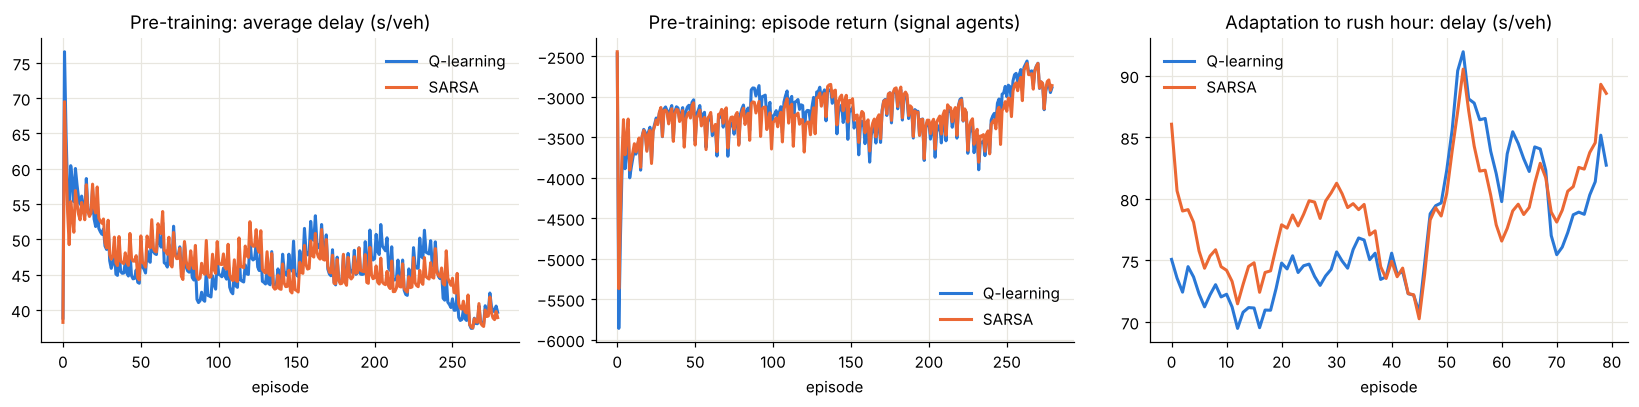

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for pol in X.ALGOS:
    sub = curves[(curves.policy == pol) & (curves.stage == "pre-train")]
    axes[0].plot(sub.episode, sub.avg_delay_s.rolling(15, min_periods=1).mean(), color=POLICY_COLORS[pol], lw=2, label=pol)
    axes[1].plot(sub.episode, sub.signal_return.rolling(15, min_periods=1).mean(), color=POLICY_COLORS[pol], lw=2, label=pol)
    ad = curves[(curves.policy == pol) & (curves.stage == "adapt") & (curves.scenario == "rush_hour")]
    axes[2].plot(ad.episode, ad.avg_delay_s.rolling(8, min_periods=1).mean(), color=POLICY_COLORS[pol], lw=2, label=pol)
axes[0].set(title="Pre-training: average delay (s/veh)", xlabel="episode")
axes[1].set(title="Pre-training: episode return (signal agents)", xlabel="episode")
axes[2].set(title="Adaptation to rush hour: delay (s/veh)", xlabel="episode")
for ax in axes: ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [10]:
kpi = X.evaluate_policies(models, CFG)
summary = kpi.groupby(["scenario", "policy"])[["avg_delay_s", "throughput_vph", "co2_kg", "conflicts_per_1000",
                                                "safety_score", "ped_avg_wait_s", "jaywalks", "bus_on_time_pct"]].mean()
summary.round(2)

  eval normal       delay  Fixed-time:  32.1  Actuated:  29.6  Q-learning:  30.4  SARSA:  30.1


  eval rush_hour    delay  Fixed-time: 109.3  Actuated:  87.5  Q-learning:  69.1  SARSA:  79.0


  eval incident     delay  Fixed-time:  38.7  Actuated:  32.6  Q-learning:  32.6  SARSA:  32.4


  eval rain         delay  Fixed-time:  33.5  Actuated:  30.1  Q-learning:  30.2  SARSA:  30.0


  eval sandstorm    delay  Fixed-time:  32.8  Actuated:  28.6  Q-learning:  28.7  SARSA:  28.8


  eval event_surge  delay  Fixed-time:  90.6  Actuated:  65.4  Q-learning:  46.6  SARSA:  47.7


  eval bus_corridor delay  Fixed-time:  33.6  Actuated:  30.9  Q-learning:  32.3  SARSA:  32.3


avg_delay_s  throughput_vph   co2_kg  conflicts_per_1000  safety_score  ped_avg_wait_s  jaywalks  bus_on_time_pct
scenario     policy                                                                                                                       
bus_corridor Actuated          30.88          7607.4  1480.82                7.79         56.22           20.59     30.00            66.04
             Fixed-time        33.58          7595.4  1504.12                9.05         52.52           18.57     16.25            63.04
             Q-learning        32.34          7600.8  1486.18                8.22         54.89           20.62     37.75            60.58
             SARSA             32.27          7600.2  1485.35                8.23         54.87           20.56     36.88            62.81
event_surge  Actuated          65.35          8373.6  1771.00               10.30         49.27           21.63     85.88            49.27
             Fixed-time        90.59          7989.6  1743.41                9.98         50.08           18.99     47.88            50.93
             Q-learning        46.65          8497.2  1729.85               11.86         45.76           23.18    124.38            51.77
             SARSA             47.67          8503.5  1731.21               12.80         43.88           23.97    145.88            46.98
incident     Actuated          32.61          7199.4  1397.09                7.83         56.10           20.47     30.88            63.42
             Fixed-time        38.70          7187.1  1426.46                9.15         52.24           18.61     16.38            55.20
             Q-learning        32.64          7197.0  1393.44                8.16         55.06           20.64     36.25            60.98
             SARSA             32.39          7190.7  1394.27                8.31         54.62           20.18     33.62            69.64
normal       Actuated          29.58          6927.9  1338.07                7.48         57.23           20.39     30.38            72.26
             Fixed-time        32.14          6916.5  1357.39                8.87         53.01           18.59     17.50            73.99
             Q-learning        30.42          6924.9  1331.99                7.58         56.89           20.78     35.00            77.17
             SARSA             30.15          6924.0  1336.81                7.92         55.81           19.87     30.25            70.04
rain         Actuated          30.06          6601.8  1292.09               11.83         45.81           19.81     16.62            52.91
             Fixed-time        33.48          6583.2  1318.13               15.04         39.94           18.21      8.50            56.17
             Q-learning        30.25          6597.9  1282.75               11.75         46.00           20.42     21.50            57.66
             SARSA             30.03          6600.0  1289.50               12.37         44.71           19.92     18.38            66.04
rush_hour    Actuated          87.49         11486.7  2692.08               10.37         49.09           21.60     60.88            59.02
             Fixed-time       109.32         11053.5  2751.02               10.20         49.53           19.03     33.88            51.21
             Q-learning        69.08         11945.1  2632.85               11.80         45.88           24.39    124.50            60.51
             SARSA             78.99         11754.6  2653.04               11.33         46.90           23.77    103.12            58.32
sandstorm    Actuated          28.56          5837.7  1128.92               12.53         44.39           19.17      7.75            57.88
             Fixed-time        32.77          5822.4  1160.49               18.07         35.65           17.18      3.00            54.30
             Q-learning        28.72          5838.3  1124.62               13.12         43.25           19.59      8.00            

In [11]:
# % change against the fixed-time plan (negative delay / CO2 / conflicts = better)
rows = []
for sc in C.SCENARIO_ORDER:
    base = kpi[(kpi.scenario == sc) & (kpi.policy == "Fixed-time")].mean(numeric_only=True)
    for pol in ["Actuated", "Q-learning", "SARSA"]:
        m = kpi[(kpi.scenario == sc) & (kpi.policy == pol)].mean(numeric_only=True)
        rows.append(dict(scenario=C.SCENARIOS[sc]["label"], policy=pol,
                         delay_pct=100 * (m.avg_delay_s - base.avg_delay_s) / base.avg_delay_s,
                         co2_pct=100 * (m.co2_kg - base.co2_kg) / base.co2_kg,
                         conflicts_pct=100 * (m.conflicts_per_1000 - base.conflicts_per_1000) / base.conflicts_per_1000,
                         ped_wait_pct=100 * (m.ped_avg_wait_s - base.ped_avg_wait_s) / base.ped_avg_wait_s))
improve = pd.DataFrame(rows)
improve.pivot(index="scenario", columns="policy", values="delay_pct").round(1)

policy,Actuated,Q-learning,SARSA
scenario,,,
Bus-priority corridor,-8.0,-3.7,-3.9
Incident / blockage,-15.7,-15.7,-16.3
Normal flow,-8.0,-5.4,-6.2
Public event surge,-27.9,-48.5,-47.4
Rain,-10.2,-9.6,-10.3
Rush hour,-20.0,-36.8,-27.7
Sandstorm,-12.9,-12.4,-12.2


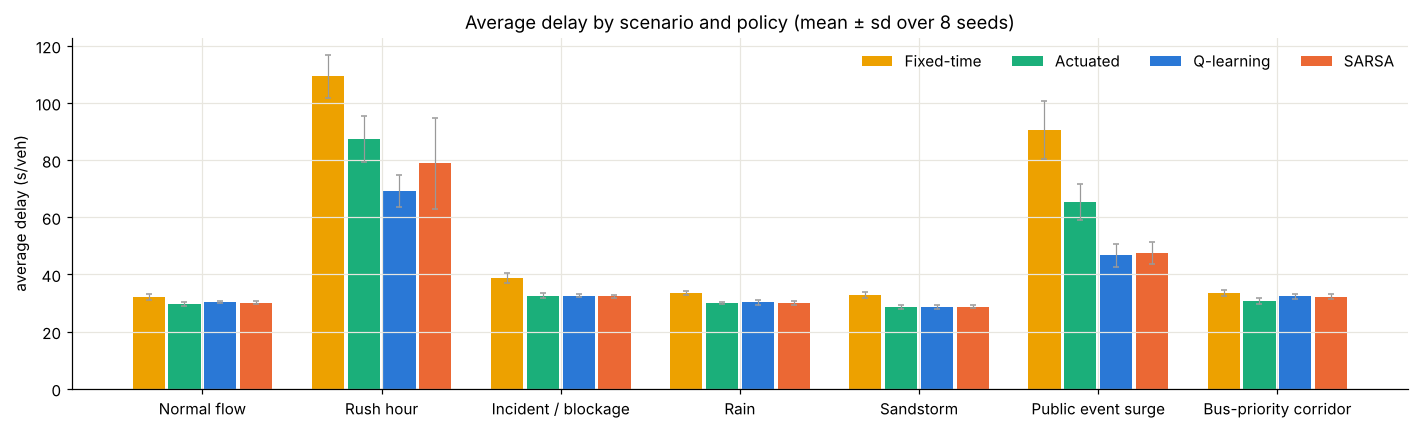

In [12]:
fig, ax = plt.subplots(figsize=(13, 4))
g = kpi.groupby(["scenario", "policy"]).avg_delay_s.agg(["mean", "std"]).reset_index()
w = 0.2
for k, pol in enumerate(A.POLICY_ORDER):
    sub = g[g.policy == pol].set_index("scenario").reindex(C.SCENARIO_ORDER)
    x = np.arange(len(C.SCENARIO_ORDER)) + (k - 1.5) * w
    ax.bar(x, sub["mean"], w * 0.9, yerr=sub["std"], color=POLICY_COLORS[pol], label=pol, capsize=2, error_kw=dict(lw=0.8, ecolor="#999"))
ax.set_xticks(np.arange(len(C.SCENARIO_ORDER)), [C.SCENARIOS[s]["label"] for s in C.SCENARIO_ORDER])
ax.set_ylabel("average delay (s/veh)"); ax.legend(frameon=False, ncol=4); ax.set_title("Average delay by scenario and policy (mean ± sd over 8 seeds)")
plt.tight_layout(); plt.show()

In [13]:
# Q-learning vs SARSA, paired by seed (common random numbers)
from scipy import stats
rows = []
for sc in C.SCENARIO_ORDER:
    a = kpi[(kpi.scenario == sc) & (kpi.policy == "Q-learning")].sort_values("seed")
    b = kpi[(kpi.scenario == sc) & (kpi.policy == "SARSA")].sort_values("seed")
    rows.append(dict(scenario=sc, q_learning=a.avg_delay_s.mean(), sarsa=b.avg_delay_s.mean(),
                     sarsa_minus_q=(b.avg_delay_s.values - a.avg_delay_s.values).mean(),
                     p_value=stats.ttest_rel(b.avg_delay_s, a.avg_delay_s).pvalue if len(a) > 1 else np.nan))
pd.DataFrame(rows).round(3)

,scenario,q_learning,sarsa,sarsa_minus_q,p_value
0,normal,30.422,30.149,-0.273,0.294
1,rush_hour,69.080,78.992,9.912,0.041
2,incident,32.640,32.392,-0.247,0.436
3,rain,30.247,30.027,-0.220,0.346
4,sandstorm,28.719,28.786,0.067,0.767
5,event_surge,46.646,47.666,1.019,0.024
6,bus_corridor,32.343,32.267,-0.076,0.814


In [14]:
abl = X.ablations(models, CFG, verbose=False)
abl.groupby(["study", "scenario", "variant"])[["avg_delay_s", "av_avg_delay_s", "bus_avg_delay_s", "bus_on_time_pct"]].mean().round(1)

avg_delay_s  av_avg_delay_s  bus_avg_delay_s  bus_on_time_pct
study            scenario     variant                                                                                   
AV routing       incident     Cooperative RL routing              32.6            32.6             32.5             61.0
                              Selfish RL routing                  32.7            32.6             32.3             68.6
                              Static routes                       33.7            33.9             36.7             59.5
                 normal       Cooperative RL routing              30.4            30.6             17.5             77.2
                              Selfish RL routing                  30.6            30.7             27.4             72.6
                              Static routes                       30.2            30.5             18.5             73.8
                 rush_hour    Cooperative RL routing              69.1            62.8             39.6             60.5
                              Selfish RL routing                  75.9            70.9             41.5             56.5
                              Static routes                       88.6            88.0             41.7             62.8
Bus priority     bus_corridor Always request TSP                  32.9            31.5             26.3             61.8
                              Learned (Q-learning)                32.3            31.2             24.1             60.6
                              No priority                         32.6            31.5             28.5             61.8
                 normal       Always request TSP                  30.2            30.1             29.4             70.0
                              Learned (Q-learning)                30.4            30.6             17.5             77.2
                              No priority                         30.1            30.2             35.1             74.5
                 rush_hour    Always request TSP                  69.1            62.5             39.2             59.0
                              Learned (Q-learning)                69.1            62.8             39.6             60.5
                              No priority                         71.1            64.2             46.2             60.3
Signal x routing event_surge  Actuated + Cooperative RL           62.9            62.7             45.1             52.2
                              Actuated + Static                   65.4            65.7             45.4             49.3
                              Fixed-time + Cooperative RL         90.8            91.2             56.1             50.6
                              Fixed-time + Static                 90.6            90.9             55.4             50.9
                              Q-learning + Cooperative RL         46.6            44.2             31.2             51.8
                              Q-learning + Static                 54.1            54.4             33.5             53.2
                              SARSA + Cooperative RL              47.7            45.9             37.0             47.0
                              SARSA + Static                      53.0            53.3             35.6             55.4
                 incident     Actuated + Cooperative RL           31.7            31.3             29.5             59.9
                              Actuated + Static                   32.6            32.7             32.0             63.4
                              Fixed-time + Cooperative RL         34.5            33.6             41.6             60.7
                              Fixed-time + Static                 38.7            39.3             51.9             55.2
                              Q-learning + Cooperative RL         32.6            32.6             32.5             61.0
                              Q-learning + Static                 

## 5. Criteria evaluation with a decision network — `decision_network.py`

The decision network (influence diagram) turns the simulation results into a **probabilistic, multi-criteria decision analysis**:

* **Chance nodes:** *Weather* {Clear, Rain, Sandstorm}, *Traffic density* {Low, Medium, High}, *Pedestrian flow* {Low, Medium, High} (operating conditions); *Congestion*, *Collision risk*, *Emissions* {Low, Medium, High}; *Health impact* {Low, High}.
* **Decision nodes:** *Signal timing* {Fixed-time, Actuated, Q-learning, SARSA}; *Routing* {Static, Cooperative RL}.
* **Utility nodes:** $U_{\text{efficiency}}(\text{Congestion})$, $U_{\text{safety}}(\text{Collision risk})$, $U_{\text{environment}}(\text{Emissions}, \text{Health})$, combined by multi-attribute utility $U = w_{e} U_{\text{eff}} + w_{s} U_{\text{safe}} + w_{v} U_{\text{env}}$ with default weights 0.40 / 0.35 / 0.25.
* **Dependencies:** Density, Weather, Signal, Routing → Congestion; Weather, Pedestrian flow, Congestion, Signal → Collision risk; Congestion, Signal → Emissions → Health impact ← Pedestrian flow (the *congestion → emissions → health* chain).

**Learning the CPTs from the simulator.** Every junction × 10-minute window of every run is one sample. Congestion is discretised by HCM level of service (LOS A / B / C-or-worse), collision risk and emissions at the tertiles of the pooled data, and each CPT is the Dirichlet(1) posterior mean $P(x\mid \text{pa}) = (n_{x,\text{pa}}+1)/(n_{\text{pa}}+|X|)$ — maximum likelihood with Laplace smoothing, as in the Probability Models lab. Priors on weather, density, pedestrian flow and the health CPT are expert assumptions. RL policies enter with the tables adapted to the matching conditions.

**Inference** is exact enumeration: $EU(d\mid e) = \sum_x P(x\mid e, d)\,U(x, d)$, the same factor-product-and-sum computation as the food-delivery example in the Utility Theory lecture.

In [15]:
%%writefile decision_network.py
"""
decision_network.py - an influence diagram for evaluating traffic-control policies.

Structure (chance = oval, decision = rectangle, utility = diamond):

    Weather ----------------+---------------------> Pedestrian flow
       |                    |                            |      \\
       v                    v                            v       v
    Congestion <-- Density  Collision risk <-------------+    Health impact
    ^   ^   |               ^   ^                                ^
    |   |   +---------------+   |                                |
    |   |   +--> Emissions -----)--------------------------------+
    |   |            ^          |
  Signal timing -----+----------+         Routing --> Congestion
    (decision)                              (decision)

    U_efficiency(Congestion)   U_safety(Collision risk)   U_environment(Emissions, Health)

* Weather, Density and Pedestrian flow are the uncertain operating conditions.
* Signal timing {Fixed-time, Actuated, Q-learning, SARSA} and Routing {Static,
  Cooperative RL} are the city's decisions.
* P(Congestion | Density, Weather, Signal, Routing), P(Collision risk | Weather, Ped, Congestion,
  Signal) and P(Emissions | Congestion, Signal) are LEARNED from the simulator: every
  junction x 10-minute window of every run is one sample, discretised into Low / Medium /
  High (congestion by HCM level of service A / B / C-or-worse; collision risk and
  emissions at the tertiles of the pooled simulated distribution), and counted with a
  Dirichlet(1) prior (Laplace smoothing = Bayesian parameter learning). RL policies enter
  with the tables adapted to the matching scenario (an operator deploys the rain-adapted
  agents when it rains).
* P(Health | Emissions, Ped) and the priors are expert-specified assumptions.
* The utility is multi-attribute (MAUT): U = w_eff U_eff + w_safe U_safe + w_env U_env.

Inference is exact enumeration (the joint has < 1,000 cells per decision).
"""
from __future__ import annotations

import itertools
import string

import numpy as np
import pandas as pd


# ======================================================================================
# A small, generic decision-network engine
# ======================================================================================
class DecisionNetwork:
    def __init__(self):
        self.chance = {}       # name -> dict(states, parents, cpt)
        self.decisions = {}    # name -> states
        self.utilities = {}    # name -> dict(parents, table)
        self.order = []        # chance-node order (topological)

    def add_chance(self, name, states, parents=(), cpt=None):
        self.chance[name] = dict(states=list(states), parents=list(parents),
                                 cpt=None if cpt is None else np.asarray(cpt, float))
        self.order.append(name)

    def add_decision(self, name, states):
        self.decisions[name] = list(states)

    def add_utility(self, name, parents, table):
        self.utilities[name] = dict(parents=list(parents), table=np.asarray(table, float))

    def card(self, name):
        if name in self.chance:
            return len(self.chance[name]["states"])
        return len(self.decisions[name])

    def states(self, name):
        return self.chance[name]["states"] if name in self.chance else self.decisions[name]

    def check(self):
        for n, nd in self.chance.items():
            shape = tuple(self.card(p) for p in nd["parents"]) + (self.card(n),)
            assert nd["cpt"].shape == shape, (n, nd["cpt"].shape, shape)
            assert np.allclose(nd["cpt"].sum(-1), 1.0), f"CPT of {n} does not sum to 1"
        return True

    # ----------------------------------------------------------------------------------
    def joint(self, decision: dict, evidence: dict | None = None):
        """Posterior joint over all chance nodes for a fixed decision, given evidence."""
        evidence = evidence or {}
        letters = {n: string.ascii_letters[k] for k, n in enumerate(self.order)}
        factors, subs = [], []
        for n in self.order:
            nd = self.chance[n]
            f = nd["cpt"]
            idx, sub = [], ""
            for p in nd["parents"]:
                if p in self.decisions:
                    idx.append(self.decisions[p].index(decision[p]))
                else:
                    idx.append(slice(None))
                    sub += letters[p]
            idx.append(slice(None))
            factors.append(f[tuple(idx)])
            subs.append(sub + letters[n])
        for n, val in evidence.items():
            ind = np.zeros(self.card(n))
            ind[self.states(n).index(val)] = 1.0
            factors.append(ind)
            subs.append(letters[n])
        out = "".join(letters[n] for n in self.order)
        J = np.einsum(",".join(subs) + "->" + out, *factors)
        z = J.sum()
        return J / z if z > 0 else J, z

    def marginal(self, J, name):
        axis = tuple(k for k, n in enumerate(self.order) if n != name)
        return J.sum(axis=axis)

    def expected_utility(self, decision: dict, evidence=None, weights=None):
        J, z = self.joint(decision, evidence)
        weights = weights or {u: 1.0 for u in self.utilities}
        comps = {}
        for u, ud in self.utilities.items():
            par = ud["parents"]
            keep = [self.order.index(p) for p in par]
            axis = tuple(k for k in range(len(self.order)) if k not in keep)
            M = J.sum(axis=axis)
            # M has the parents in network order; transpose to the utility's parent order
            net_order = sorted(keep)
            perm = [net_order.index(self.order.index(p)) for p in par]
            M = np.transpose(M, perm) if len(perm) > 1 else M
            comps[u] = float(np.sum(M * ud["table"]))
        total = float(sum(weights.get(u, 0.0) * v for u, v in comps.items()))
        post = {n: self.marginal(J, n) for n in self.order}
        return dict(total=total, components=comps, posteriors=post, evidence_prob=z)

    def decision_table(self, evidence=None, weights=None):
        names = list(self.decisions)
        rows = []
        for combo in itertools.product(*[self.decisions[n] for n in names]):
            d = dict(zip(names, combo))
            r = self.expected_utility(d, evidence, weights)
            row = dict(d)
            row["EU"] = r["total"]
            row.update({f"E[{u}]": v for u, v in r["components"].items()})
            for n in ("Congestion", "Collision risk", "Emissions", "Health impact"):
                if n in r["posteriors"]:
                    for s, p in zip(self.states(n), r["posteriors"][n]):
                        row[f"P({n}={s})"] = float(p)
            rows.append(row)
        df = pd.DataFrame(rows).sort_values("EU", ascending=False).reset_index(drop=True)
        return df

    def best(self, evidence=None, weights=None):
        t = self.decision_table(evidence, weights)
        return t.iloc[0].to_dict(), t

    def value_of_information(self, var, evidence=None, weights=None):
        """EVPI of observing chance node `var` before choosing (var must not depend on
        the decisions)."""
        evidence = dict(evidence or {})
        base_best, base_table = self.best(evidence, weights)
        dec0 = {n: base_best[n] for n in self.decisions}
        post = self.expected_utility(dec0, evidence, weights)["posteriors"][var]
        value = 0.0
        detail = []
        for s, p in zip(self.states(var), post):
            if p <= 0:
                continue
            e2 = dict(evidence)
            e2[var] = s
            b, _ = self.best(e2, weights)
            value += p * b["EU"]
            detail.append(dict(state=s, prob=float(p), best_signal=b.get("Signal timing"),
                               best_routing=b.get("Routing"), EU=b["EU"]))
        return dict(variable=var, evpi=float(value - base_best["EU"]),
                    eu_without=float(base_best["EU"]), eu_with=float(value), detail=detail)


# ======================================================================================
# The traffic decision network
# ======================================================================================
WEATHER = ["Clear", "Rain", "Sandstorm"]
DENSITY = ["Low", "Medium", "High"]
PED = ["Low", "Medium", "High"]
LEVELS3 = ["Low", "Medium", "High"]
SIGNAL = ["Fixed-time", "Actuated", "Q-learning", "SARSA"]
ROUTING = ["Static", "Cooperative RL"]

# ---- expert-specified pieces (assumptions the group must defend) ---------------------
PRIOR_WEATHER = [0.82, 0.06, 0.12]           # Dubai: mostly clear; dust events > rain days
PRIOR_DENSITY = [0.30, 0.45, 0.25]           # share of operating hours: off-peak/inter-peak/peak
P_PED_GIVEN_WEATHER = [[0.25, 0.50, 0.25],   # Clear:     Low / Medium / High
                       [0.50, 0.40, 0.10],   # Rain
                       [0.70, 0.25, 0.05]]   # Sandstorm
P_HEALTH_HIGH = {                             # P(Health impact = High | Emissions, Ped flow)
    ("Low", "Low"): 0.05, ("Low", "Medium"): 0.08, ("Low", "High"): 0.15,
    ("Medium", "Low"): 0.20, ("Medium", "Medium"): 0.28, ("Medium", "High"): 0.40,
    ("High", "Low"): 0.45, ("High", "Medium"): 0.58, ("High", "High"): 0.75,
}
U_EFF = [100.0, 60.0, 10.0]                   # Congestion Low / Medium / High
U_SAFE = [100.0, 50.0, 0.0]                   # Collision risk Low / Medium / High
U_EMIS = [100.0, 55.0, 10.0]                  # Emissions Low / Medium / High
U_HEALTH = [100.0, 0.0]                       # Health impact Low / High
DEFAULT_WEIGHTS = {"U_efficiency": 0.40, "U_safety": 0.35, "U_environment": 0.25}

# HCM signalised-intersection level of service by control delay per junction (s/veh):
# Low = LOS A (<= 10 s), Medium = LOS B (10-20 s), High = LOS C or worse (> 20 s)
LOS_EDGES = [10.0, 20.0]


def discretise(samples: pd.DataFrame, risk_edges=None, emis_edges=None, cong_edges=None,
               congestion_by_los=True):
    """Congestion by HCM level of service; risk and emissions at pooled tertiles."""
    df = samples.copy()
    risk_edges = risk_edges or list(np.quantile(df["conflicts_per_1000"], [1 / 3, 2 / 3]))
    emis_edges = emis_edges or list(np.quantile(df["co2_g_per_veh"], [1 / 3, 2 / 3]))
    if congestion_by_los:
        cong_edges = LOS_EDGES
    cong_edges = cong_edges or list(np.quantile(df["delay_per_veh_s"], [1 / 3, 2 / 3]))
    df["Congestion"] = pd.cut(df["delay_per_veh_s"], [-np.inf] + list(cong_edges) + [np.inf],
                              labels=LEVELS3).astype(str)
    df["Collision risk"] = pd.cut(df["conflicts_per_1000"],
                                  [-np.inf] + risk_edges + [np.inf], labels=LEVELS3).astype(str)
    df["Emissions"] = pd.cut(df["co2_g_per_veh"], [-np.inf] + emis_edges + [np.inf],
                             labels=LEVELS3).astype(str)
    return df, dict(congestion=[float(x) for x in cong_edges],
                    risk=[float(x) for x in risk_edges],
                    emissions=[float(x) for x in emis_edges])


def learn_cpt(df, child, child_states, parents, parent_states, alpha=1.0):
    """Dirichlet(alpha) posterior mean of P(child | parents) from counts."""
    shape = tuple(len(s) for s in parent_states) + (len(child_states),)
    counts = np.zeros(shape)
    idx_maps = [{s: k for k, s in enumerate(ps)} for ps in parent_states]
    cmap = {s: k for k, s in enumerate(child_states)}
    cols = list(parents) + [child]
    for row, n in df.groupby(cols).size().items():
        row = row if isinstance(row, tuple) else (row,)
        key = tuple(m[v] for m, v in zip(idx_maps, row[:-1])) + (cmap[row[-1]],)
        counts[key] += n
    cpt = (counts + alpha) / (counts.sum(-1, keepdims=True) + alpha * len(child_states))
    return cpt, counts


def build_traffic_network(samples: pd.DataFrame, alpha: float = 1.0, edges=None):
    edges = edges or {}
    df, edges = discretise(samples, edges.get("risk"), edges.get("emissions"),
                           edges.get("congestion"))
    dn = DecisionNetwork()
    dn.add_decision("Signal timing", SIGNAL)
    dn.add_decision("Routing", ROUTING)
    dn.add_chance("Weather", WEATHER, (), PRIOR_WEATHER)
    dn.add_chance("Traffic density", DENSITY, (), PRIOR_DENSITY)
    dn.add_chance("Pedestrian flow", PED, ("Weather",), np.array(P_PED_GIVEN_WEATHER))
    df = df.rename(columns={"weather": "Weather", "density": "Traffic density",
                            "ped_flow": "Pedestrian flow", "signal": "Signal timing",
                            "routing": "Routing"})
    cg, n_cg = learn_cpt(df, "Congestion", LEVELS3,
                         ["Traffic density", "Weather", "Signal timing", "Routing"],
                         [DENSITY, WEATHER, SIGNAL, ROUTING], alpha)
    dn.add_chance("Congestion", LEVELS3,
                  ("Traffic density", "Weather", "Signal timing", "Routing"), cg)
    cr, n_cr = learn_cpt(df, "Collision risk", LEVELS3,
                         ["Weather", "Pedestrian flow", "Congestion", "Signal timing"],
                         [WEATHER, PED, LEVELS3, SIGNAL], alpha)
    dn.add_chance("Collision risk", LEVELS3,
                  ("Weather", "Pedestrian flow", "Congestion", "Signal timing"), cr)
    em, n_em = learn_cpt(df, "Emissions", LEVELS3, ["Congestion", "Signal timing"],
                         [LEVELS3, SIGNAL], alpha)
    dn.add_chance("Emissions", LEVELS3, ("Congestion", "Signal timing"), em)
    hi = np.zeros((3, len(PED), 2))
    for a, e in enumerate(LEVELS3):
        for b, p in enumerate(PED):
            q = P_HEALTH_HIGH[(e, p)]
            hi[a, b] = [1 - q, q]
    dn.add_chance("Health impact", ["Low", "High"], ("Emissions", "Pedestrian flow"), hi)
    dn.add_utility("U_efficiency", ("Congestion",), U_EFF)
    dn.add_utility("U_safety", ("Collision risk",), U_SAFE)
    u_env = np.array([[0.7 * U_EMIS[a] + 0.3 * U_HEALTH[b] for b in range(2)]
                      for a in range(3)])
    dn.add_utility("U_environment", ("Emissions", "Health impact"), u_env)
    dn.check()
    dn.counts = {"Congestion": n_cg, "Collision risk": n_cr, "Emissions": n_em}
    dn.edges = edges
    dn.data = df
    return dn


# ---- scenario -> evidence mapping -----------------------------------------------------
SCENARIO_EVIDENCE = {
    "normal": {"Weather": "Clear", "Traffic density": "Medium", "Pedestrian flow": "Medium"},
    "rush_hour": {"Weather": "Clear", "Traffic density": "High", "Pedestrian flow": "Medium"},
    "incident": {"Weather": "Clear", "Traffic density": "High", "Pedestrian flow": "Medium"},
    "rain": {"Weather": "Rain", "Traffic density": "Medium"},
    "sandstorm": {"Weather": "Sandstorm", "Traffic density": "Medium"},
    "event_surge": {"Weather": "Clear", "Traffic density": "High", "Pedestrian flow": "High"},
    "bus_corridor": {"Weather": "Clear", "Traffic density": "Medium", "Pedestrian flow": "Medium"},
}


def cpt_frame(dn: DecisionNetwork) -> pd.DataFrame:
    rows = []
    for n in dn.order:
        nd = dn.chance[n]
        par = nd["parents"]
        cnt = getattr(dn, "counts", {}).get(n)
        for combo in itertools.product(*[range(dn.card(p)) for p in par]):
            probs = nd["cpt"][combo] if par else nd["cpt"]
            row = {"node": n, "parents": " | ".join(par) if par else "(prior)"}
            row["parent_values"] = ", ".join(f"{p}={dn.states(p)[k]}" for p, k in
                                             zip(par, combo)) if par else ""
            for s, pr in zip(nd["states"], probs):
                row[f"P={s}"] = round(float(pr), 4)
            row["samples"] = int(cnt[combo].sum()) if cnt is not None else ""
            rows.append(row)
    return pd.DataFrame(rows)


def scenario_decisions(dn, weights=None):
    rows = []
    for sc, ev in SCENARIO_EVIDENCE.items():
        t = dn.decision_table(ev, weights)
        for rank, r in t.iterrows():
            d = dict(scenario=sc, rank=rank + 1, evidence=", ".join(f"{k}={v}"
                                                                    for k, v in ev.items()))
            d.update(r.to_dict())
            rows.append(d)
    return pd.DataFrame(rows)


def weight_sensitivity(dn, evidence=None, step=0.05, routing=None):
    """Best signal policy over the weight simplex (w_eff + w_safe + w_env = 1)."""
    rows = []
    n = int(round(1 / step))
    for a in range(n + 1):
        for b in range(n + 1 - a):
            w = {"U_efficiency": a * step, "U_safety": b * step,
                 "U_environment": 1 - (a + b) * step}
            t = dn.decision_table(evidence, w)
            if routing:
                t = t[t["Routing"] == routing]
            top = t.iloc[0]
            rows.append(dict(w_efficiency=round(w["U_efficiency"], 3),
                             w_safety=round(w["U_safety"], 3),
                             w_environment=round(w["U_environment"], 3),
                             best_signal=top["Signal timing"], best_routing=top["Routing"],
                             EU=float(top["EU"])))
    return pd.DataFrame(rows)


def pgmpy_crosscheck(dn, decision, evidence):
    """Optional: recompute the same expected utility with pgmpy (as used in the
    Probability Models lab). Decisions enter as root nodes fixed by evidence."""
    try:
        from pgmpy.factors.discrete import TabularCPD
        from pgmpy.inference import VariableElimination
        try:
            from pgmpy.models import DiscreteBayesianNetwork as BN
        except ImportError:                     # older pgmpy
            from pgmpy.models import BayesianNetwork as BN
    except ImportError:
        return None
    edges = []
    for n, nd in dn.chance.items():
        for p in nd["parents"]:
            edges.append((p, n))
    model = BN(edges)
    cpds = []
    for dname, st in dn.decisions.items():
        cpds.append(TabularCPD(dname, len(st), [[1 / len(st)] for _ in st],
                               state_names={dname: st}))
    for n, nd in dn.chance.items():
        par = nd["parents"]
        card = dn.card(n)
        if par:
            vals = nd["cpt"].reshape(-1, card).T
            cpds.append(TabularCPD(n, card, vals, evidence=par,
                                   evidence_card=[dn.card(p) for p in par],
                                   state_names={n: nd["states"],
                                                **{p: dn.states(p) for p in par}}))
        else:
            cpds.append(TabularCPD(n, card, [[x] for x in nd["cpt"]],
                                   state_names={n: nd["states"]}))
    model.add_cpds(*cpds)
    model.check_model()
    inf = VariableElimination(model)
    ev = dict(evidence)
    ev.update(decision)
    total = {}
    for u, ud in dn.utilities.items():
        q = inf.query(ud["parents"], evidence=ev, show_progress=False)
        vals = q.values
        order = q.variables
        perm = [order.index(p) for p in ud["parents"]]
        vals = np.transpose(vals, perm) if len(perm) > 1 else vals
        total[u] = float(np.sum(vals * ud["table"]))
    return total

Writing decision_network.py


In [16]:
import decision_network as D
dn_data = X.dn_samples(models, CFG, verbose=False)
dn = D.build_traffic_network(dn_data)
print("samples:", len(dn_data), "| discretisation edges:", {k: [round(x, 2) for x in v] for k, v in dn.edges.items()})
D.cpt_frame(dn).query("node == 'Congestion'").head(12)

samples: 11664 | discretisation edges: {'congestion': [10.0, 20.0], 'risk': [3.51, 4.93], 'emissions': [39.32, 46.97]}


,node,parents,parent_values,P=Clear,P=Rain,P=Sandstorm,samples,P=Low,P=Medium,P=High
5,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.8061,0.1879,0.0061
6,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.8121,0.1818,0.0061
7,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9515,0.0424,0.0061
8,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9576,0.0364,0.0061
9,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9394,0.0545,0.0061
10,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9576,0.0364,0.0061
11,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9273,0.0667,0.0061
12,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Clear, Signal tim...",NaN,NaN,NaN,162,0.9515,0.0424,0.0061
13,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Rain, Signal timi...",NaN,NaN,NaN,162,0.7576,0.2364,0.0061
14,Congestion,Traffic density | Weather | Signal timing | Ro...,"Traffic density=Low, Weather=Rain, Signal timi...",NaN,NaN,NaN,162,0.7394,0.2545,0.0061


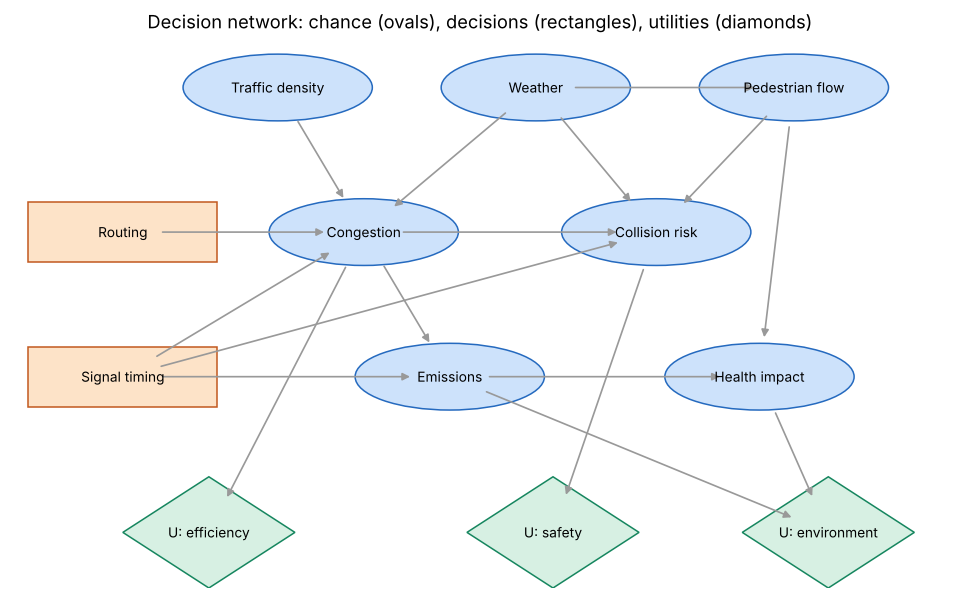

In [17]:
# draw the influence diagram
import matplotlib.patches as mpatches
LAYOUT = {"Traffic density": (0.4, 2.6), "Weather": (1.9, 2.6), "Pedestrian flow": (3.4, 2.6), "Routing": (-0.5, 1.3),
          "Congestion": (0.9, 1.3), "Collision risk": (2.6, 1.3), "Signal timing": (-0.5, 0.0), "Emissions": (1.4, 0.0),
          "Health impact": (3.2, 0.0), "U_efficiency": (0.0, -1.4), "U_safety": (2.0, -1.4), "U_environment": (3.6, -1.4)}
fig, ax = plt.subplots(figsize=(11, 6.5)); ax.set_axis_off()
edges = [(p, n) for n, nd in dn.chance.items() for p in nd["parents"]] + [(p, u) for u, ud in dn.utilities.items() for p in ud["parents"]]
for a, b in edges:
    ax.annotate("", xy=LAYOUT[b], xytext=LAYOUT[a], arrowprops=dict(arrowstyle="-|>", color="#999", lw=1.1, shrinkA=26, shrinkB=26))
for n, (x, y) in LAYOUT.items():
    if n in dn.chance:   patch = mpatches.Ellipse((x, y), 1.1, 0.6, fc="#cde2fb", ec="#256abf")
    elif n in dn.decisions: patch = mpatches.Rectangle((x - 0.55, y - 0.27), 1.1, 0.54, fc="#fde3c8", ec="#c2591f")
    else: patch = mpatches.RegularPolygon((x, y), 4, radius=0.5, fc="#d7f0e3", ec="#16865f")
    ax.add_patch(patch); ax.text(x, y, n.replace("U_", "U: "), ha="center", va="center", fontsize=9)
ax.set_xlim(-1.15, 4.3); ax.set_ylim(-1.9, 3.05); ax.set_title("Decision network: chance (ovals), decisions (rectangles), utilities (diamonds)")
plt.show()

In [18]:
# expected utility of every decision pair, overall and per scenario
best, table_all = dn.best({}, D.DEFAULT_WEIGHTS)
print("Recommended with no evidence (priors only):", best["Signal timing"], "+", best["Routing"], f"EU = {best['EU']:.2f}")
table_all[["Signal timing", "Routing", "EU", "E[U_efficiency]", "E[U_safety]", "E[U_environment]",
           "P(Congestion=High)", "P(Collision risk=High)"]].round(3)

Recommended with no evidence (priors only): Actuated + Cooperative RL EU = 79.55


,Signal timing,Routing,EU,E[U_efficiency],E[U_safety],E[U_environment],P(Congestion=High),P(Collision risk=High)
0,Actuated,Cooperative RL,79.552,83.430,84.988,65.736,0.077,0.067
1,Actuated,Static,78.346,81.527,84.300,64.921,0.108,0.071
2,Q-learning,Cooperative RL,76.049,79.606,78.964,66.278,0.132,0.098
3,Q-learning,Static,75.195,78.435,78.339,65.611,0.150,0.104
4,SARSA,Cooperative RL,74.750,78.920,78.362,63.020,0.138,0.104
5,SARSA,Static,74.642,78.706,78.279,63.046,0.145,0.103
6,Fixed-time,Cooperative RL,69.654,74.699,74.234,55.172,0.124,0.137
7,Fixed-time,Static,68.594,73.048,73.709,54.307,0.148,0.139


In [19]:
sd = D.scenario_decisions(dn, D.DEFAULT_WEIGHTS)
sd[sd["rank"] <= 2][["scenario", "evidence", "rank", "Signal timing", "Routing", "EU", "E[U_efficiency]", "E[U_safety]", "E[U_environment]"]].round(2)

,scenario,evidence,rank,Signal timing,Routing,EU,E[U_efficiency],E[U_safety],E[U_environment]
0,normal,"Weather=Clear, Traffic density=Medium, Pedestr...",1,Actuated,Cooperative RL,89.87,92.91,97.69,74.08
1,normal,"Weather=Clear, Traffic density=Medium, Pedestr...",2,Q-learning,Cooperative RL,89.40,91.70,96.89,75.23
8,rush_hour,"Weather=Clear, Traffic density=High, Pedestria...",1,Actuated,Cooperative RL,57.60,48.24,85.79,33.12
9,rush_hour,"Weather=Clear, Traffic density=High, Pedestria...",2,Actuated,Static,55.00,43.64,83.42,33.38
16,incident,"Weather=Clear, Traffic density=High, Pedestria...",1,Actuated,Cooperative RL,57.60,48.24,85.79,33.12
17,incident,"Weather=Clear, Traffic density=High, Pedestria...",2,Actuated,Static,55.00,43.64,83.42,33.38
24,rain,"Weather=Rain, Traffic density=Medium",1,Actuated,Static,79.52,93.64,66.20,75.58
25,rain,"Weather=Rain, Traffic density=Medium",2,Actuated,Cooperative RL,78.38,92.67,64.91,74.39
32,sandstorm,"Weather=Sandstorm, Traffic density=Medium",1,Actuated,Cooperative RL,79.42,94.61,63.59,77.26
33,sandstorm,"Weather=Sandstorm, Traffic density=Medium",2,Actuated,Static,77.86,93.39,61.58,75.79


In [20]:
# value of (perfect) information: is it worth observing a condition before choosing?
pd.DataFrame([{k: v for k, v in dn.value_of_information(v_, {}, D.DEFAULT_WEIGHTS).items() if k != "detail"}
              for v_ in ["Weather", "Traffic density", "Pedestrian flow"]]).round(3)

,variable,evpi,eu_without,eu_with
0,Weather,0.0,79.552,79.552
1,Traffic density,-0.0,79.552,79.552
2,Pedestrian flow,0.0,79.552,79.552


In [21]:
# sensitivity of the best signal policy to the stakeholder weights (efficiency, safety, environment)
for ev in [{}, {"Traffic density": "High"}, {"Weather": "Sandstorm"}]:
    ws = D.weight_sensitivity(dn, ev, step=0.1)
    print(ev or "no evidence", "->", ws.best_signal.value_counts().to_dict())

no evidence -> {'Actuated': 64, 'Q-learning': 2}


{'Traffic density': 'High'} -> {'Actuated': 66}


{'Weather': 'Sandstorm'} -> {'Actuated': 65, 'Q-learning': 1}


In [22]:
# cross-check our enumeration against pgmpy (the library used in the Probability Models lab)
try:
    import pgmpy  # noqa: F401
except ImportError:
    !pip -q install pgmpy
decision = {"Signal timing": "Q-learning", "Routing": "Cooperative RL"}
evidence = {"Weather": "Sandstorm", "Traffic density": "High"}
ours = dn.expected_utility(decision, evidence)["components"]
theirs = D.pgmpy_crosscheck(dn, decision, evidence)
pd.DataFrame({"this notebook": ours, "pgmpy VariableElimination": theirs}).round(6)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,this notebook,pgmpy VariableElimination
U_efficiency,35.393939,35.393939
U_safety,6.754630,6.754630
U_environment,32.818705,32.818705


## Findings (full run, 8 held-out seeds per scenario)

1. **Against the fixed-time plan**, the multi-agent RL policies cut average delay in every scenario: Q-learning by 4–49 % (rush hour −37 %, event surge −49 %) and SARSA by 4–47 %, with 1–4 % less CO₂ and up to 8 % more throughput.
2. **Against vehicle-actuated control**, RL wins where the network is stressed (rush hour −21 % for Q-learning and −10 % for SARSA; event surge −29 % and −27 %) and is within ±5 % elsewhere.
3. **The gain has a safety cost under congestion.** In rush hour and the event surge the RL policies hold longer greens, so pedestrians wait 22–28 % longer and expected conflicts rise 11–28 % against fixed-time, and jaywalking rises 45–105 % against actuated control. In light traffic they *reduce* conflicts by 9–27 % against fixed-time.
4. **Signal × routing decomposition.** Cooperative AV routing is the largest single lever in rush hour (actuated signals 87.5 → 65.0 s/veh; Q-learning signals 88.6 → 69.1 s). With that routing in place, the actuated rule is the best signal controller in rush hour, while the RL signal agents are clearly best in the event surge (46.6 vs 62.9 s).
5. **Decision network.** With weights 0.40 / 0.35 / 0.25, *actuated signals + cooperative RL routing* has the highest expected utility in 22 of the 27 weather × density × pedestrian conditions (Q-learning signals win in light, clear-weather traffic; static routing in medium-density rain), because the RL signals' pedestrian and conflict risk lowers the safety utility. With safety weighted at 0.6, fixed-time becomes the best signal choice in clear weather with high density and high pedestrian flow. The event surge's localised crowd is outside the network's generic conditions, so there the direct simulation, which favours RL signals, is the better guide.
6. **Q-learning vs SARSA.** In the main run Q-learning beat SARSA in rush hour (69.1 vs 79.0 s, paired t-test over evaluation seeds p = 0.04) and narrowly in the event surge (46.6 vs 47.7 s, p = 0.02); elsewhere the difference is not significant. That test covers evaluation noise only: re-adapting with three other seeds gave SARSA 68–70 s and Q-learning 71–75 s in rush hour, and 48–55 s against 48–79 s in the event surge. The gap between the algorithms is therefore mostly training variance, and SARSA's more conservative on-policy updates made it the more stable learner.

## 6. Export the data for the dashboard

The main data file, **`smart_traffic_simulation_log.csv`**, has one row per junction per 30-second window of a representative evaluation episode for every scenario × policy (queues per approach, arrivals, departures, delay, pedestrians waiting, jaywalks, expected conflicts, CO₂, NOx, stops, spillback, emergency-vehicle and bus-priority activity, shield overrides, reward). The other files hold KPIs per episode, learning curves, component studies, agent decisions, decision-network samples, scenario parameters and the trained Q-tables.

In [23]:
sim_log, anims, decisions = X.record_runs(models)
res = dict(models=models, curves=curves, kpi=kpi, ablations=abl, sim_log=sim_log, anims=anims, decisions=decisions, dn=dn_data)
X.export_all(res, "data")
for f in sorted(os.listdir("data")):
    print(f"{f:40s} {os.path.getsize(os.path.join('data', f)) / 1e6:6.2f} MB")
sim_log.head()

ablation_results.csv                       0.09 MB
agent_decisions.csv                        0.90 MB
animations.json.gz                         1.49 MB
decision_network_samples.csv               1.09 MB
kpi_results.csv                            0.05 MB
learning_curves.csv                        0.18 MB
q_tables.npz                               3.57 MB
scenario_parameters.csv                    0.00 MB
smart_traffic_simulation_log.csv           2.33 MB


,scenario,scenario_label,weather,policy,junction,street,avenue,t_start_s,ns_green_share,phase_changes,queue_n,queue_e,queue_s,queue_w,arrivals,departures,vehicle_delay_s,ped_waiting,ped_delay_s,jaywalks,expected_conflicts,co2_g,nox_g,stops,spillback_blocks,ev_present,tsp_active,overrides,reward
0,normal,Normal flow,Clear,Fixed-time,J1,Street 1,Avenue A,0,0.167,2,0.33,0.0,0.00,0.17,6,3,8.3,2.33,70.0,0,0.0156,114.5,0.034,3,0,0,0,1,-0.709
1,normal,Normal flow,Clear,Fixed-time,J1,Street 1,Avenue A,30,0.667,1,0.67,0.0,0.83,3.33,16,11,108.6,1.17,35.0,0,0.0428,550.7,0.219,13,0,0,0,1,-2.491
2,normal,Normal flow,Clear,Fixed-time,J1,Street 1,Avenue A,60,0.500,1,1.33,0.0,3.50,1.17,12,18,155.4,2.50,75.0,0,0.0379,403.9,0.219,8,0,0,0,1,-2.851
3,normal,Normal flow,Clear,Fixed-time,J1,Street 1,Avenue A,90,0.333,1,0.83,0.5,2.50,1.67,14,9,140.9,3.17,95.0,0,0.0498,713.8,0.323,10,0,0,0,1,-3.461
4,normal,Normal flow,Clear,Fixed-time,J1,Street 1,Avenue A,120,0.833,1,1.00,1.0,2.33,1.00,12,15,142.3,2.00,60.0,0,0.0201,415.1,0.212,7,0,0,0,2,-2.613


In [24]:
# download everything as one zip (Colab only)
import shutil
shutil.make_archive("smart_traffic_data", "zip", "data")
try:
    from google.colab import files
    files.download("smart_traffic_data.zip")
except Exception:
    print("Not running in Colab - the zip is at ./smart_traffic_data.zip")

Not running in Colab - the zip is at ./smart_traffic_data.zip


## 7. Dashboard

The six-tab Streamlit prototype (City Overview · RL Simulation · Decision Network Visualizer · Scenario Explorer · KPI & Trade-off Analysis · Policy Comparison) reads the files exported above. Its source (`app.py`, `viz.py`, `sim_view.py`) is in the project repository; run it locally with `streamlit run app.py`, or deploy the folder to Streamlit Community Cloud.

## References
* Kochenderfer, M. J. (2015). *Decision Making Under Uncertainty: Theory and Application.* MIT Press — ch. 3 (decision networks, value of information) and ch. 5 (Q-learning, SARSA).
* Sutton, R. S. & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press — ch. 6.
* Wairagade, A., Ugale, K. & Waghmare, R. (2025). AI-Powered Smart Traffic Management System for Urban Congestion Reduction. *IJSRET*, 11(2), 1997–2001.
* Boyan, J. A. & Littman, M. L. (1994). Packet routing in dynamically changing networks: a reinforcement learning approach. *NIPS 6*.
* Webster, F. V. (1958). *Traffic Signal Settings.* Road Research Technical Paper 39, HMSO.
* Qiu, L. & Nixon, W. A. (2008). Effects of adverse weather on traffic crashes: systematic review and meta-analysis. *Transportation Research Record*, 2055, 139–146.
* Sullivan, A., Sisiopiku, V. & Reddy-Surhabi, S. (2010). *Impacts of Signal System Timings on Rain-Related Congestion.* UTCA Report 07211 (reports Perrin et al. 2002 saturation-flow and speed reductions).
* FHWA (2013). *Guide for Highway Capacity and Operations Analysis of ATDM Strategies* (FHWA-HOP-13-042), Appendix A — HCM weather capacity adjustment factors.
* US EPA (2023). *Greenhouse Gas Emissions from a Typical Passenger Vehicle* (400 g CO₂/mile); Argonne National Laboratory, *Idling* fact sheet (0.3 gal/h car, 1 gal/h heavy vehicle).
* Transportation Research Board (2016). *Highway Capacity Manual, 6th ed.* — saturation flow, signalised-intersection LOS, pedestrian delay and non-compliance.